In [1]:
import pandas as pd
import pickle
import os
import time

import math
import random
import shutil
import pathlib
import seaborn as sns
import numpy as np
from numpy import where
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib import pyplot
import os
import time
from imblearn.over_sampling import ADASYN
from collections import (Counter, defaultdict)
import tensorflow as tf
from scipy import stats
from tensorflow.keras import layers
#from tensorflow.python import train
from keras.models import Sequential
from keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
import keras.callbacks as kcallbacks
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import (QuantileTransformer, LabelEncoder)
from sklearn.metrics import (det_curve, balanced_accuracy_score, cohen_kappa_score, hinge_loss, matthews_corrcoef, 
                             top_k_accuracy_score, hamming_loss, jaccard_score, log_loss, zero_one_loss, classification_report,
                             accuracy_score, precision_score, roc_auc_score, average_precision_score, recall_score, f1_score, 
                             mean_squared_error, mean_absolute_error, confusion_matrix, r2_score)

2024-02-08 20:25:52.983079: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-02-08 20:25:53.021312: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-02-08 20:25:53.021331: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-02-08 20:25:53.021349: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-02-08 20:25:53.028444: I tensorflow/core/platform/cpu_feature_g

# VGG16

In [ ]:
img_height = 224
img_width = 224

train_ds = tf.data.Dataset.load("saved_data/train")
val_ds = tf.data.Dataset.load("saved_data/validation")
test_ds = tf.data.Dataset.load("saved_data/test")

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

In [ ]:
IMG_SHAPE = (img_height, img_width,3)
base_model_VGG16 = tf.keras.applications.VGG16(input_shape=IMG_SHAPE, include_top=False, weights='imagenet')

In [146]:
base_model_VGG16.trainable = False
base_model_VGG16.summary()

Model: "vgg16"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_7 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 224, 224, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 224, 224, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 112, 112, 64)      0         
                                                                 
 block2_conv1 (Conv2D)       (None, 112, 112, 128)     73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 112, 112, 128)     147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 56, 56, 128)       0     

In [147]:
image_batch, label_batch = next(iter(train_ds))
feature_batch_VGG16 = base_model_VGG16(image_batch)
print(feature_batch_VGG16.shape)
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average_VGG16 = global_average_layer(feature_batch_VGG16)
print(feature_batch_average_VGG16.shape)
prediction_layer_VGG16 = tf.keras.layers.Dense(1)
prediction_batch_VGG16 = prediction_layer_VGG16(feature_batch_average_VGG16)
print(prediction_batch_VGG16.shape)

(32, 7, 7, 512)
(32, 512)
(32, 1)


In [148]:
inputs_VGG16 = tf.keras.Input(shape=(img_height, img_width,3)) 
x_VGG16 = data_augmentation(inputs_VGG16)
x_VGG16 = tf.keras.applications.vgg16.preprocess_input (x_VGG16) 
x_VGG16 = base_model_VGG16(x_VGG16, training=False)   
x_VGG16 = global_average_layer(x_VGG16)  
x_VGG16 = tf.keras.layers.Dropout(0.2)(x_VGG16) 
outputs_VGG16 = prediction_layer_VGG16(x_VGG16)
model_VGG16 = tf.keras.Model(inputs_VGG16, outputs_VGG16)  

In [149]:
class LossHistory(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs={}):
        self.losses = {'batch':[], 'epoch':[]}
        self.accuracy = {'batch':[], 'epoch':[]}
        self.val_loss = {'batch':[], 'epoch':[]}
        self.val_acc = {'batch':[], 'epoch':[]}
        self.history = {}
    def on_batch_end(self, batch, logs={}):
        self.losses['batch'].append(logs.get('loss'))
        self.accuracy['batch'].append(logs.get('accuracy'))
        self.val_loss['batch'].append(logs.get('val_loss'))
        self.val_acc['batch'].append(logs.get('val_accuracy'))
    def on_epoch_end(self, batch, logs={}):
        self.losses['epoch'].append(logs.get('loss'))
        self.accuracy['epoch'].append(logs.get('accuracy'))
        self.val_loss['epoch'].append(logs.get('val_loss'))
        self.val_acc['epoch'].append(logs.get('val_accuracy'))
        self.history = {'loss': self.losses, 'accuracy': self.accuracy, 'val_loss': self.val_loss, 'val_accuracy': self.val_acc}

In [150]:
history= LossHistory()
base_learning_rate = 0.00007
savepath='./VGG16.h5'
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
saveBestModel = kcallbacks.ModelCheckpoint(filepath=savepath, verbose=1, save_best_only=True, mode='auto')
model_VGG16.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [151]:
model_VGG16.summary()

Model: "model_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_8 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 tf.__operators__.getitem_1  (None, 224, 224, 3)       0         
  (SlicingOpLambda)                                              
                                                                 
 tf.nn.bias_add_1 (TFOpLamb  (None, 224, 224, 3)       0         
 da)                                                             
                                                                 
 vgg16 (Functional)          (None, 7, 7, 512)         14714688  
                                                                 
 global_average_pooling2d_3  (None, 512)               0   

In [152]:
initial_epochs = 5
loss0, accuracy0 = model_VGG16.evaluate(val_ds)

36/36 [==============================] - 5s 63ms/step - loss: 1.4212 - accuracy: 0.6421


In [153]:
print("initial loss: {:.4f}".format(loss0))
print("initial accuracy: {:.4f}".format(accuracy0))

initial loss: 1.4212
initial accuracy: 0.6421


In [154]:
%%time
history_VGG16 = model_VGG16.fit(train_ds, epochs=initial_epochs, validation_data=val_ds, callbacks=[early_stop, saveBestModel, history])

# Inference (Detection)
start_time = time.time()
detection_results = model_VGG16.predict(val_ds)
end_time = time.time()

detection_time = end_time - start_time

print(f"Detection time: {detection_time} seconds")

Epoch 1/5
213/213 [==============================] - ETA: 0s - loss: 1.8338 - accuracy: 0.5349
Epoch 1: val_loss improved from inf to 0.39110, saving model to ./VGG16.h5


/usr/local/lib/python3.9/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


213/213 [==============================] - 15s 64ms/step - loss: 1.8338 - accuracy: 0.5349 - val_loss: 0.3911 - val_accuracy: 0.8606
Epoch 2/5
213/213 [==============================] - ETA: 0s - loss: 0.6640 - accuracy: 0.7916
Epoch 2: val_loss improved from 0.39110 to 0.16004, saving model to ./VGG16.h5
213/213 [==============================] - 12s 55ms/step - loss: 0.6640 - accuracy: 0.7916 - val_loss: 0.1600 - val_accuracy: 0.9405
Epoch 3/5
213/213 [==============================] - ETA: 0s - loss: 0.3244 - accuracy: 0.8907
Epoch 3: val_loss improved from 0.16004 to 0.11144, saving model to ./VGG16.h5
213/213 [==============================] - 13s 59ms/step - loss: 0.3244 - accuracy: 0.8907 - val_loss: 0.1114 - val_accuracy: 0.9547
Epoch 4/5
213/213 [==============================] - ETA: 0s - loss: 0.2092 - accuracy: 0.9336
Epoch 4: val_loss improved from 0.11144 to 0.09287, saving model to ./VGG16.h5
213/213 [==============================] - 12s 58ms/step - loss: 0.2092 - accur

In [155]:
acc_VGG16 = history_VGG16.history['accuracy']
val_acc_VGG16 = history_VGG16.history['val_accuracy']
loss_VGG16 = history_VGG16.history['loss']
val_loss_VGG16 = history_VGG16.history['val_loss']

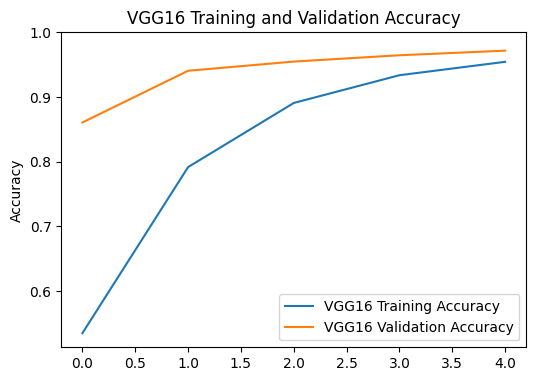

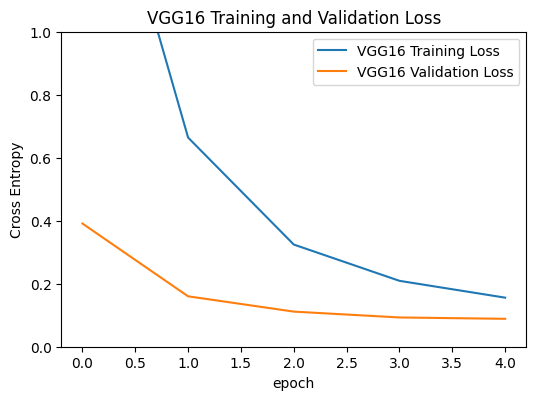

<Figure size 640x480 with 0 Axes>

In [156]:
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 1)
plt.plot(acc_VGG16, label='VGG16 Training Accuracy')
plt.plot(val_acc_VGG16, label='VGG16 Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('VGG16 Training and Validation Accuracy')
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 2)
plt.plot(loss_VGG16, label='VGG16 Training Loss')
plt.plot(val_loss_VGG16, label='VGG16 Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('VGG16 Training and Validation Loss')
plt.xlabel('epoch')

plt.savefig('VGG16_Full.pdf', format='pdf')
plt.savefig('VGG16_Full.png', format='png')
plt.show()

plt.savefig('VGG16_Full.pdf', format='pdf', dpi=300)
plt.savefig('VGG16_Full.svg', format='svg')
plt.savefig('VGG16_Full.png', format='png', dpi=300)
plt.show()

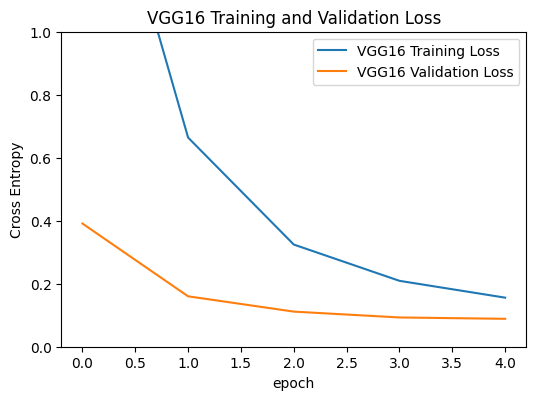

<Figure size 640x480 with 0 Axes>

In [157]:
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 2)
plt.plot(loss_VGG16, label='VGG16 Training Loss')
plt.plot(val_loss_VGG16, label='VGG16 Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('VGG16 Training and Validation Loss')
plt.xlabel('epoch')

plt.savefig('VGG16_loss.pdf', format='pdf')
plt.savefig('VGG16_loss.png', format='png')
plt.show()

plt.savefig('VGG16_loss.pdf', format='pdf', dpi=300)
plt.savefig('VGG16_loss.svg', format='svg')
plt.savefig('VGG16_loss.png', format='png', dpi=300)
plt.show()

## Test_ds (VGG)

Predictions:
 [0 1 1 0 1 1 1 0 0 0 1 1 0 1 1 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 1 0 1 0 0
 0 1 1 0 1 1 1 1 0 1 1 0 1 1 0 1 0 0 0 1 1 0 0 1 0 0 1 0 1 0 1 0 1 0 0 0 0
 0 0 1 1 0 0 0 0 1 0 0 0 1 1 1 1 0 0 1 0 1 1 1 0 1 0 0 0 1 0 1 0 0 0 0 0 1
 0 0 0 1 0 1 1 0 0 0 1 1 1 1 0 1 0 1 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 1 1 0 1
 0 0 1 0 0 0 0 1 0 1 1 0 1 0 0 0 0 1 1 0 0 0 0 0 1 0 0 1 1 1 0 0 0 0 1 1 1
 0 0 0 0 1 0 0 1 0 0 1 0 0 0 0 1 0 1 0 1 0 1 0 0 0 0 0 0 0 1 1 1 1 0 1 0 0
 1 1 0 0 0 1 1 0 1 1 0 1 0 1 1 0 0 1 0 0 0 0 1 1 1 0 1 0 1 1 0 1 1 1 1 1 0
 0 0 0 0 1 1 0 0 1 1 1 0 1 0 0 1 0 0 0 1 1 0 0 1 1 0 0 0 0 1 1 1 1 0 0 1 1
 0 0 1 0 1 1 0 1 1 0 0 1 1 1 0 0 1 0 1 0 1 0 1 1 0 0 0 1 0 0 1 0 0 0 0 0 0
 1 1 1 1 1 1 0 0 0 0 1 1 0 1 0 1 1 0 0 0 0 0 0 0 0 0 1 0 1 0 1 0 0 1 0 0 1
 0 0 0 1 0 0 0 1 1 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 0 1 0 1 0 0 1 0
 1 1 0 0 0 0 1 0 0 1 0 1 1 0 0 1 0 1 0 1 0 0 0 0 0 1 0 0 0 1 1 0 1 1 0 1 1
 0 1 0 0 0 1 1 0 0 0 0 0 0 0 0 0 1 1 0 0 1 1 0 0 0 0 0 0 1 1 1 0 1 1 1 0 0
 1 1 0 0 0 

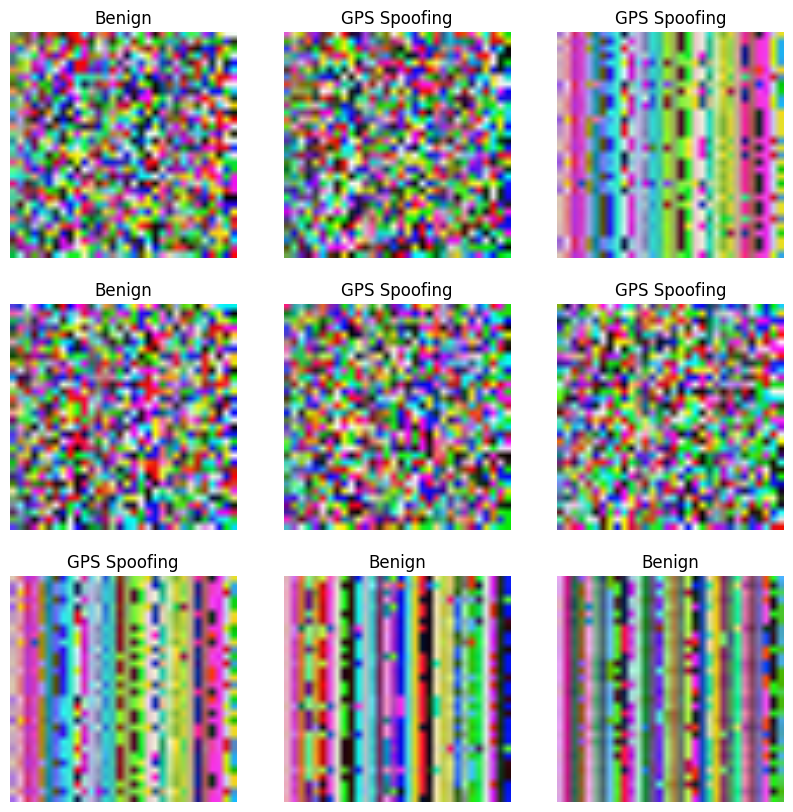

In [158]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_VGG16 = []
all_labels_VGG16 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_VGG16.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_VGG16.append(predictions)
    all_labels_VGG16.append(label_batch)

all_predictions_VGG16 = np.concatenate(all_predictions_VGG16)
all_labels_VGG16 = np.concatenate(all_labels_VGG16)
print('Predictions:\n', all_predictions_VGG16)
print('Labels:\n', all_labels_VGG16)

report_VGG16 = classification_report(all_labels_VGG16, all_predictions_VGG16, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_VGG16[i]])
    plt.axis("off")

In [159]:
cm=confusion_matrix(all_labels_VGG16 ,all_predictions_VGG16)
TP = np.sum((all_predictions_VGG16 == 1) & (all_labels_VGG16 == 1))
FP = np.sum((all_predictions_VGG16 == 1) & (all_labels_VGG16 == 0))
FN = np.sum((all_predictions_VGG16 == 0) & (all_labels_VGG16 == 1))
TN = cm[0, 0]
DA = (TP + TN) / len(all_labels_VGG16)
DP = TP / (TP + FP)
DS = TP / (TP + FN)
DF = 2 * (DP * DS) / (DP + DS)
DE = 1 - DA
FR = FP / (FP + TN)
total_predictions = TP + FP + TN + FN
prediction_overhead = (TP + FP) / total_predictions
TN, FP, FN, TP = confusion_matrix(all_labels_VGG16, all_predictions_VGG16).ravel()
specificity = TN / (TN + FP)

test_ds (VGG16)
                  
              precision    recall  f1-score   support

      Benign       0.97      1.00      0.99       331
GPS Spoofing       1.00      0.96      0.98       245

    accuracy                           0.98       576
   macro avg       0.99      0.98      0.98       576
weighted avg       0.98      0.98      0.98       576

                  
1) Accuracy: 0.984375
                  
2) Precision: 0.9847886029411765
                  
3) Recall: 0.984375
                  
4) Average F1-score: 0.9843336077967224
                  
5) F1-score for each type of attack: [0.98658718 0.98128898]
                  
6) Average ROC AUC: 0.9816326530612245
                  
7) Average PR AUC: 0.978890306122449
                  
8) Balanced Accuracy: 0.9816326530612245
                  
9) Hinge: 0.5902777777777778
                  
10) Matthews Correlation Coefficient: 0.9683837601089441
                  
11) Jaccard Score: 0.963265306122449
             

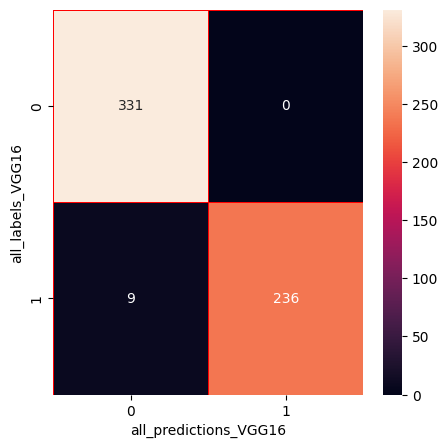

In [160]:
print("test_ds (VGG16)")
print("                  ")
print(report_VGG16)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_VGG16 , all_predictions_VGG16, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))
print("                  ")

cm=confusion_matrix(all_labels_VGG16 ,all_predictions_VGG16)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_VGG16")
plt.ylabel("all_labels_VGG16")
plt.show()

In [161]:
loss_test_VGG16, accuracy_test_VGG16 = model_VGG16.evaluate(test_ds)
print("Test Loss: {:.4f}".format(loss_test_VGG16))
print("Test Accuracy: {:.4f}".format(accuracy_test_VGG16))             

18/18 [==============================] - 1s 40ms/step - loss: 0.0614 - accuracy: 0.9844
Test Loss: 0.0614
Test Accuracy: 0.9844


In [162]:
saved_info = {
    'class_names': class_names,
    'all_labels_VGG16': all_labels_VGG16,
    'all_predictions_VGG16': all_predictions_VGG16,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_VGG16 , all_predictions_VGG16),
    'precision_score': precision_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'recall_score': recall_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'f1_score_each': f1_score(all_labels_VGG16 , all_predictions_VGG16, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_VGG16 , all_predictions_VGG16),
    'Hinge': hinge_loss(all_labels_VGG16 , all_predictions_VGG16),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_VGG16 , all_predictions_VGG16),
    'Jaccard Score': jaccard_score(all_labels_VGG16 , all_predictions_VGG16),
    'Log Loss': log_loss(all_labels_VGG16 , all_predictions_VGG16),
    'Zero-One Loss': zero_one_loss(all_labels_VGG16 , all_predictions_VGG16),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('VGG16_test_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [163]:
with open('VGG16_test_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_VGG16'])
print("  ")
print("predictions:", saved_info['all_predictions_VGG16'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 1 1 0 1 1 1 0 0 0 1 1 0 1 1 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 1 0 1 0 0
 0 1 1 0 1 1 1 1 0 1 1 0 1 1 0 1 0 0 0 1 1 0 0 1 0 0 1 0 1 0 1 0 1 0 0 0 0
 0 0 1 1 0 0 0 0 1 0 0 0 1 1 1 1 0 0 1 0 1 1 1 0 1 0 0 0 1 0 1 0 0 0 0 0 1
 0 0 0 1 0 1 1 0 0 0 1 1 1 1 0 1 0 1 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 1 1 0 1
 1 0 1 0 0 0 0 1 0 1 1 0 1 0 0 0 0 1 1 1 0 0 0 0 1 0 0 1 1 1 0 0 0 0 1 1 1
 0 0 0 0 1 0 0 1 1 0 1 0 0 0 0 1 0 1 0 1 0 1 0 0 0 0 0 0 0 1 1 1 1 0 1 0 0
 1 1 0 0 0 1 1 0 1 1 0 1 0 1 1 0 0 1 0 0 0 0 1 1 1 0 1 0 1 1 0 1 1 1 1 1 0
 0 0 0 0 1 1 0 0 1 1 1 0 1 0 0 1 0 0 1 1 1 0 0 1 1 0 0 0 0 1 1 1 1 0 0 1 1
 0 0 1 0 1 1 0 1 1 0 0 1 1 1 0 0 1 0 1 0 1 0 1 1 0 0 0 1 0 0 1 0 0 0 0 0 0
 1 1 1 1 1 1 0 0 0 0 1 1 0 1 0 1 1 0 0 0 0 0 0 0 0 0 1 0 1 0 1 0 0 1 0 0 1
 0 0 0 1 0 0 0 1 1 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 0 1 0 1 0 0 1 0
 1 1 0 0 0 0 1 0 0 1 1 1 1 0 0 1 0 1 0 1 0 0 0 1 0 1 0 0 0 1 1 0 1 1 0 1 1
 0 1 0 0 0 1 1 0 0 0 0 0 0 0 0 0 1 1 0 0 1 1 0 0 0 0 0 1 1 1 1 0 1

## Val_ds (VGG16)

Predictions:
 [1 0 0 ... 1 0 0]
Labels:
 [1 0 0 ... 1 0 0]


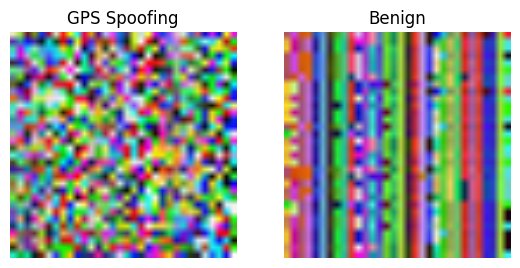

In [164]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_VGG16 = []
all_labels_VGG16 = []
for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_VGG16.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_VGG16.append(predictions)
    all_labels_VGG16.append(label_batch)
    
all_predictions_VGG16 = np.concatenate(all_predictions_VGG16)
all_labels_VGG16 = np.concatenate(all_labels_VGG16)
print('Predictions:\n', all_predictions_VGG16)
print('Labels:\n', all_labels_VGG16)
report_VGG16 = classification_report(all_labels_VGG16, all_predictions_VGG16, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_VGG16[i]])
    plt.axis("off")

val_ds (VGG16)
                  
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98       640
GPS Spoofing       1.00      0.95      0.97       486

    accuracy                           0.98      1126
   macro avg       0.98      0.97      0.98      1126
weighted avg       0.98      0.98      0.98      1126

                  
1) Accuracy: 0.977797513321492
                  
2) Precision: 0.9786321932718118
                  
3) Recall: 0.977797513321492
                  
4) Average F1-score: 0.9777171173722865
                  
5) F1-score for each type of attack: [0.98084291 0.97360084]
                  
6) Average ROC AUC: 0.9742798353909465
                  
7) Average PR AUC: 0.970762157460401
                  
8) Balanced Accuracy: 0.9742798353909465
                  
9) Hinge: 0.5905861456483126
                  
10) Matthews Correlation Coefficient: 0.9554577608573672
                  
11) Jaccard Score: 0.948559670781

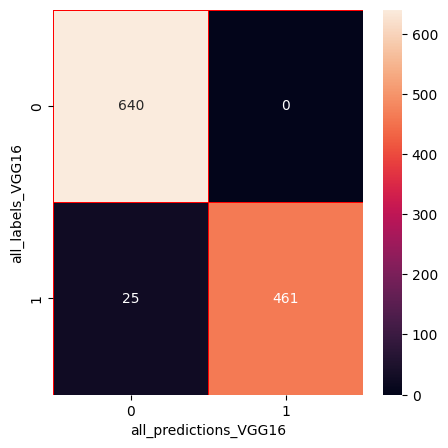

In [165]:
print("val_ds (VGG16)")
print("                  ")
print(report_VGG16)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_VGG16 , all_predictions_VGG16, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_VGG16 , all_predictions_VGG16)))
print("  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))
print("                  ")

cm=confusion_matrix(all_labels_VGG16 ,all_predictions_VGG16)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_VGG16")
plt.ylabel("all_labels_VGG16")
plt.show()

In [166]:
loss_val_VGG16, accuracy_val_VGG16 = model_VGG16.evaluate(val_ds)
print("val Loss: {:.4f}".format(loss_val_VGG16))
print("val Accuracy: {:.4f}".format(accuracy_val_VGG16))

36/36 [==============================] - 4s 55ms/step - loss: 0.0789 - accuracy: 0.9725
val Loss: 0.0789
val Accuracy: 0.9725


In [167]:
saved_info = {
    'class_names': class_names,
    'all_labels_VGG16': all_labels_VGG16,
    'all_predictions_VGG16': all_predictions_VGG16,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_VGG16 , all_predictions_VGG16),
    'precision_score': precision_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'recall_score': recall_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'f1_score_each': f1_score(all_labels_VGG16 , all_predictions_VGG16, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_VGG16 , all_predictions_VGG16),
    'Cohens Kappa': cohen_kappa_score(all_labels_VGG16 , all_predictions_VGG16),
    'Hinge': hinge_loss(all_labels_VGG16 , all_predictions_VGG16),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_VGG16 , all_predictions_VGG16),
    'Jaccard Score': jaccard_score(all_labels_VGG16 , all_predictions_VGG16),
    'Log Loss': log_loss(all_labels_VGG16 , all_predictions_VGG16),
    'Zero-One Loss': zero_one_loss(all_labels_VGG16 , all_predictions_VGG16),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('VGG16_val_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [168]:
with open('VGG16_val_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_VGG16'])
print("  ")
print("predictions:", saved_info['all_predictions_VGG16'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [1 0 0 ... 1 0 0]
  
predictions: [1 0 0 ... 1 0 0]
  
cm: [[640   0]
 [ 25 461]]
  
1) Accuracy: 0.977797513321492
  
2) Precision: 0.9786321932718118
  
3) Recall: 0.977797513321492
  
4) Average F1-score: 0.9777171173722865
  
5) F1-score for each type of attack: [0.98084291 0.97360084]
  
6) Average ROC AUC: 0.9742798353909465
  
7) Average PR AUC: 0.970762157460401
  
8) Balanced Accuracy: 1.0
  
9) Hinge: 0.5905861456483126
  
10) Matthews Correlation Coefficient: 0.9554577608573672
  
11) Jaccard Score: 0.948559670781893
  
12) Log Loss: 0.8002587342166333
  
13) Zero-One Loss: 0.022202486678507993
  
14) Prediction Overhead: 0.4097222222222222
  
15) Specificity: 1.0


## TL (VGG16)

In [169]:
base_model_VGG16.trainable = True
print("Number of layers in the base model: ", len(base_model_VGG16.layers))
fine_tune_at_VGG16 = int((130/151)*len(base_model_VGG16.layers))
for layer in base_model_VGG16.layers[:fine_tune_at_VGG16]:
  layer.trainable = False
print("frozen layers in the base model from layer 1 to ", fine_tune_at_VGG16 )
print("unfrozen layers in the base model from %2d to %3d " % (fine_tune_at_VGG16+1,len(base_model_VGG16.layers)))

Number of layers in the base model:  19
frozen layers in the base model from layer 1 to  16
unfrozen layers in the base model from 17 to  19 


In [170]:
history= LossHistory()
savepath='./VGG16+TL.h5'
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
saveBestModel = kcallbacks.ModelCheckpoint(filepath=savepath, verbose=1, save_best_only=True, mode='auto')
model_VGG16.compile(loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              optimizer = tf.keras.optimizers.Adam(learning_rate=0.00005/10),
              metrics=['accuracy'])
model_VGG16.summary()
len(model_VGG16.trainable_variables)

Model: "model_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_8 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 tf.__operators__.getitem_1  (None, 224, 224, 3)       0         
  (SlicingOpLambda)                                              
                                                                 
 tf.nn.bias_add_1 (TFOpLamb  (None, 224, 224, 3)       0         
 da)                                                             
                                                                 
 vgg16 (Functional)          (None, 7, 7, 512)         14714688  
                                                                 
 global_average_pooling2d_3  (None, 512)               0   

6

In [171]:
%%time
fine_tune_epochs = 5
total_epochs =  initial_epochs + fine_tune_epochs
history_fine_VGG16 = model_VGG16.fit(train_ds, epochs=total_epochs, initial_epoch=history_VGG16.epoch[-1],
                         validation_data=val_ds, callbacks=[early_stop, saveBestModel, history])

# Inference (Detection)
start_time = time.time()
detection_results = model_VGG16.predict(val_ds)
end_time = time.time()

detection_time = end_time - start_time

print(f"Detection time: {detection_time} seconds")

Epoch 5/10
212/213 [============================>.] - ETA: 0s - loss: 0.0584 - accuracy: 0.9849
Epoch 5: val_loss improved from inf to 0.04793, saving model to ./VGG16+TL.h5


/usr/local/lib/python3.9/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


213/213 [==============================] - 16s 67ms/step - loss: 0.0582 - accuracy: 0.9850 - val_loss: 0.0479 - val_accuracy: 0.9840
Epoch 6/10
213/213 [==============================] - ETA: 0s - loss: 0.0314 - accuracy: 0.9909
Epoch 6: val_loss improved from 0.04793 to 0.03606, saving model to ./VGG16+TL.h5
213/213 [==============================] - 13s 62ms/step - loss: 0.0314 - accuracy: 0.9909 - val_loss: 0.0361 - val_accuracy: 0.9867
Epoch 7/10
213/213 [==============================] - ETA: 0s - loss: 0.0224 - accuracy: 0.9921
Epoch 7: val_loss improved from 0.03606 to 0.03152, saving model to ./VGG16+TL.h5
213/213 [==============================] - 14s 66ms/step - loss: 0.0224 - accuracy: 0.9921 - val_loss: 0.0315 - val_accuracy: 0.9885
Epoch 8/10
213/213 [==============================] - ETA: 0s - loss: 0.0171 - accuracy: 0.9947
Epoch 8: val_loss improved from 0.03152 to 0.02116, saving model to ./VGG16+TL.h5
213/213 [==============================] - 13s 62ms/step - loss: 0.

## VGG16 Graph

In [172]:
acc_VGG16 += history_fine_VGG16.history['accuracy']
val_acc_VGG16 += history_fine_VGG16.history['val_accuracy']
loss_VGG16 += history_fine_VGG16.history['loss']
val_loss_VGG16 += history_fine_VGG16.history['val_loss']

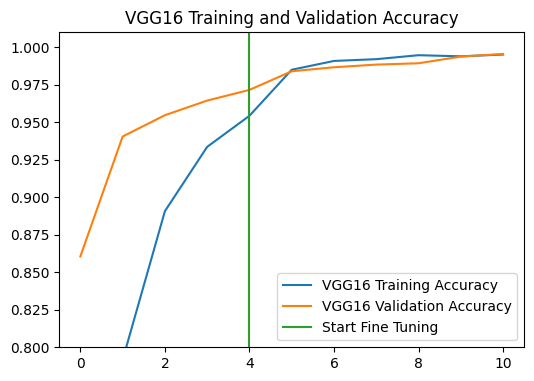

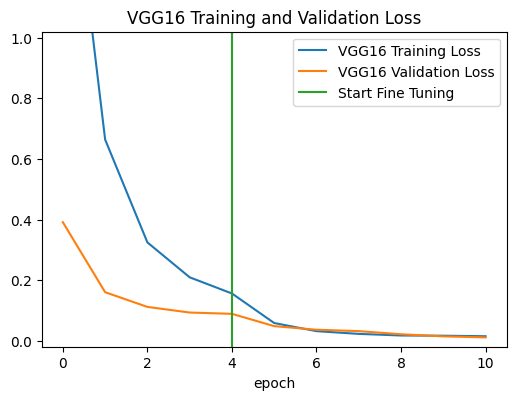

In [173]:
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 1)
plt.plot(acc_VGG16, label='VGG16 Training Accuracy')
plt.plot(val_acc_VGG16, label='VGG16 Validation Accuracy')
plt.ylim([0.8, 1.01])
plt.plot([initial_epochs-1,initial_epochs-1],
          plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='lower right')
plt.title('VGG16 Training and Validation Accuracy')

plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 2)
plt.plot(loss_VGG16, label='VGG16 Training Loss')
plt.plot(val_loss_VGG16, label='VGG16 Validation Loss')
plt.ylim([-0.02, 1.02])
plt.plot([initial_epochs-1,initial_epochs-1],
         plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='upper right')
plt.title('VGG16 Training and Validation Loss')
plt.xlabel('epoch')

training_history = {}
training_history['train_loss'] = history_VGG16.history['loss']
training_history['val_loss'] = history_VGG16.history['val_loss']
training_history['train_acc'] = history_VGG16.history['accuracy']
training_history['val_acc'] = history_VGG16.history['val_accuracy']

with open('VGG16_TL+ORG.pkl', 'wb') as file:
    pickle.dump(training_history, file)
plt.savefig('VGG16_TL+ORG.pdf', format='pdf', dpi=300)
plt.savefig('VGG16_TL+ORG.svg', format='svg')
plt.savefig('VGG16_TL+ORG.png', format='png', dpi=300)
plt.show()

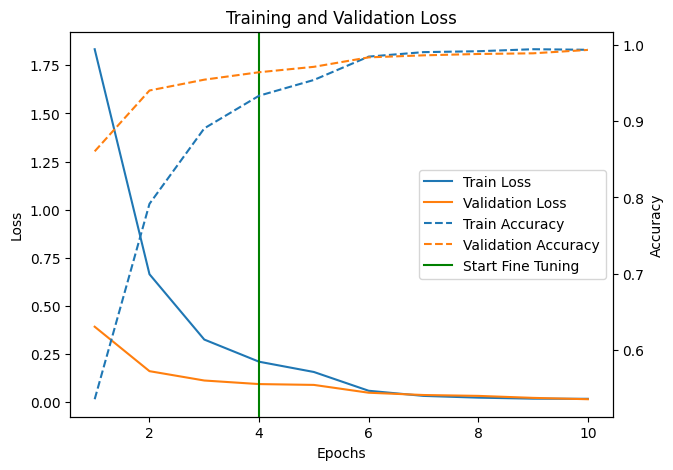

In [174]:
actual_epochs = range(1, total_epochs + 1)  
actual_train_loss = loss_VGG16[:total_epochs]  
actual_val_loss = val_loss_VGG16[:total_epochs]  
actual_train_accuracy = acc_VGG16[:total_epochs]  
actual_val_accuracy = val_acc_VGG16[:total_epochs]

fig, ax1 = plt.subplots(figsize=(7, 5))
ax1.plot(actual_epochs, actual_train_loss, '-', label='Train Loss')
ax1.plot(actual_epochs, actual_val_loss, '-', label='Validation Loss')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss')
ax2 = ax1.twinx()
ax2.plot(actual_epochs, actual_train_accuracy, '--', label='Train Accuracy')
ax2.plot(actual_epochs, actual_val_accuracy, '--', label='Validation Accuracy')
ax2.set_ylabel('Accuracy')

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
custom_legend_elements = handles1 + handles2 + [plt.Line2D([0], [0], color='green', label='Start Fine Tuning')]
custom_legend_labels = labels1 + labels2 + ['Start Fine Tuning']
ax1.legend(custom_legend_elements, custom_legend_labels, loc='center right')
ax1.axvline(x=initial_epochs - 1, color='green')
plot_data = {'fig': fig, 'ax1': ax1, 'ax2': ax2}

learning_curve_data = {
    'train_loss': actual_train_loss,
    'val_loss': actual_val_loss,
    'train_acc': actual_train_accuracy,
    'val_acc': actual_val_accuracy
}

with open('VGG16+Start Fine Tuning.pkl', 'wb') as file:
    pickle.dump(plot_data, file)
plt.savefig('VGG16+Start Fine Tuning.pdf', format='pdf', dpi=300)
plt.savefig('VGG16+Start Fine Tuning.svg', format='svg')
plt.savefig('VGG16+Start Fine Tuning.png', format='png', dpi=300)
plt.show()

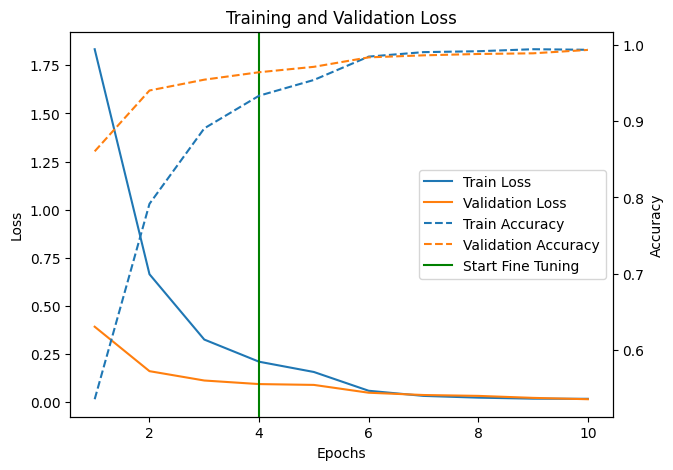

Training Loss: [1.833784580230713, 0.6639727354049683, 0.324363112449646, 0.209163635969162, 0.15577365458011627, 0.05816146731376648, 0.03141525760293007, 0.02236948348581791, 0.017060227692127228, 0.01634565182030201]
Validation Loss: [0.39109838008880615, 0.1600424200296402, 0.11143729090690613, 0.09287270903587341, 0.08858432620763779, 0.04793150722980499, 0.03605717793107033, 0.03151850029826164, 0.021159477531909943, 0.014165697619318962]
Training Accuracy: [0.5348802804946899, 0.7915993332862854, 0.8907328248023987, 0.9336172938346863, 0.9543251395225525, 0.9850198030471802, 0.9908943772315979, 0.9920693039894104, 0.9947128891944885, 0.9939785599708557]
Validation Accuracy: [0.8605684041976929, 0.9404973387718201, 0.9547069072723389, 0.9644760489463806, 0.9715808033943176, 0.9840142130851746, 0.9866784811019897, 0.9884546995162964, 0.9893428087234497, 0.9937832951545715]


In [175]:
with open('VGG16+Start Fine Tuning.pkl', 'rb') as file:
    learning_curve = pickle.load(file)
fig = learning_curve['fig']
ax1 = learning_curve['ax1']
ax2 = learning_curve['ax2']
plt.show()

train_loss = learning_curve_data['train_loss']
val_loss = learning_curve_data['val_loss']
train_acc = learning_curve_data['train_acc']
val_acc = learning_curve_data['val_acc']
print("Training Loss:", learning_curve_data['train_loss'])
print("Validation Loss:", learning_curve_data['val_loss'])
print("Training Accuracy:", learning_curve_data['train_acc'])
print("Validation Accuracy:", learning_curve_data['val_acc'])

## Test_ds (VGG16) + TL

Predictions:
 [1 1 1 1 0 0 1 0 1 1 0 0 1 1 1 1 1 1 1 1 0 1 0 1 0 1 0 1 0 0 1 0 1 1 0 0 0
 1 0 1 1 1 1 0 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 1 0 1 0
 0 0 0 0 1 1 0 0 0 0 0 0 1 1 0 0 0 0 1 0 1 1 0 0 1 0 0 1 1 1 1 1 0 0 1 0 0
 0 1 0 0 0 0 0 1 1 0 0 0 1 1 0 0 0 0 1 0 0 0 1 0 0 0 0 0 1 1 0 1 0 0 0 1 0
 0 1 1 1 0 1 0 0 0 0 0 1 0 0 1 0 1 0 1 0 0 0 0 0 0 1 1 1 0 0 1 0 1 0 1 0 0
 1 1 1 1 0 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 0 0 0 1 0 1 0 0 0 1 0 1 0 1 0 1 0
 1 0 0 1 1 0 1 1 0 1 0 0 0 0 0 0 0 1 1 1 0 1 1 1 0 1 0 1 0 1 1 0 1 1 0 0 0
 1 1 0 0 0 0 0 1 0 1 1 0 1 0 1 0 1 1 1 1 1 0 1 1 0 1 0 0 0 0 0 1 1 0 1 1 1
 1 1 0 0 0 0 1 0 0 0 0 1 1 1 1 1 1 0 0 1 0 1 1 0 1 0 0 1 1 0 0 1 0 0 0 1 0
 0 0 0 1 1 0 1 0 0 1 0 0 0 1 1 0 0 1 1 1 1 1 1 1 0 0 0 0 1 1 0 0 1 1 0 1 0
 0 0 0 1 0 0 1 0 0 0 1 1 1 0 0 1 0 0 0 1 0 1 1 0 0 0 0 1 0 0 0 1 0 0 0 1 0
 1 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 0 1 0 0 0 1 1 0 0 0 0 1 0 1 0 1 0 0 0 1 1
 0 0 0 1 0 0 0 0 0 0 0 0 1 1 1 0 0 0 1 0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 1 1 1
 0 0 0 0 1 

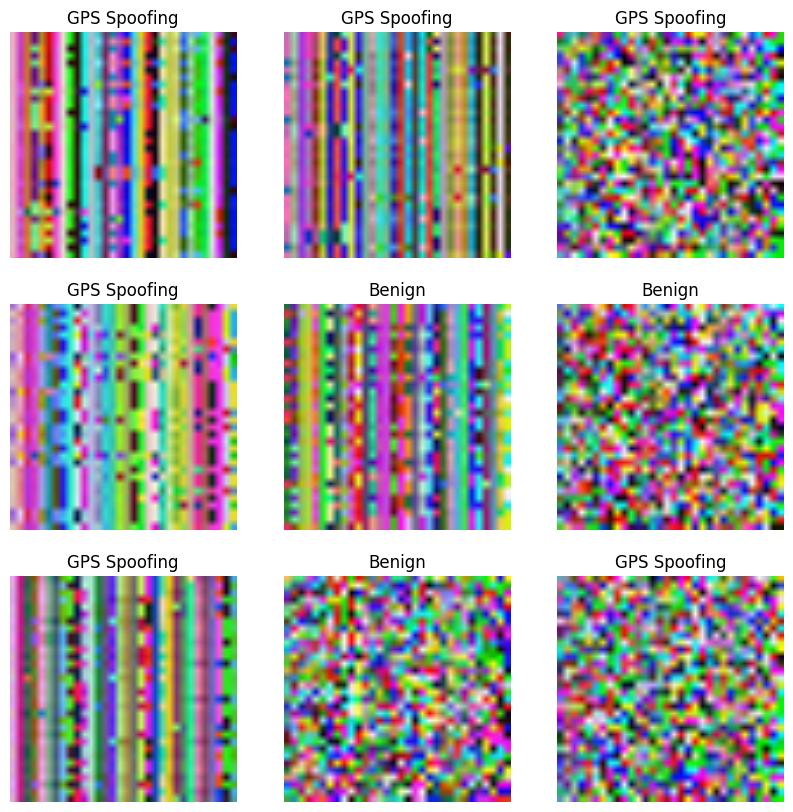

In [176]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_VGG16 = []
all_labels_VGG16 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_VGG16.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_VGG16.append(predictions)
    all_labels_VGG16.append(label_batch)
    
all_predictions_VGG16 = np.concatenate(all_predictions_VGG16)
all_labels_VGG16 = np.concatenate(all_labels_VGG16)
print('Predictions:\n', all_predictions_VGG16)
print('Labels:\n', all_labels_VGG16)

report_VGG16 = classification_report(all_labels_VGG16, all_predictions_VGG16, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_VGG16[i]])
    plt.axis("off")

test_ds (VGG16)
                  
              precision    recall  f1-score   support

      Benign       0.99      1.00      1.00       335
GPS Spoofing       1.00      0.99      0.99       241

    accuracy                           0.99       576
   macro avg       1.00      0.99      0.99       576
weighted avg       0.99      0.99      0.99       576

                  
1) Accuracy: 0.9947916666666666
                  
2) Precision: 0.9948378944773175
                  
3) Recall: 0.9947916666666666
                  
4) Average F1-score: 0.9947869651153292
                  
5) F1-score for each type of attack: [0.99554235 0.99373695]
                  
6) Average ROC AUC: 0.9937759336099585
                  
7) Average PR AUC: 0.9927602005532503
                  
8) Balanced Accuracy: 0.9937759336099585
                  
9) Hinge: 0.5868055555555556
                  
10) Matthews Correlation Coefficient: 0.9893364513453291
                  
11) Jaccard Score: 0.98755186

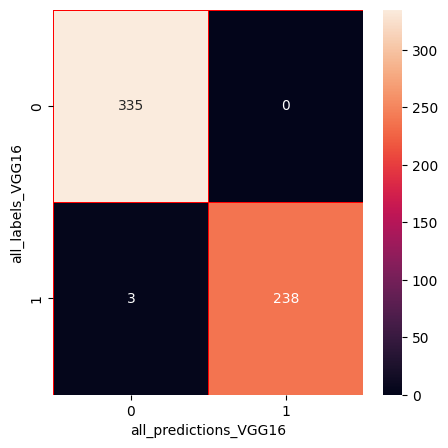

In [177]:
print("test_ds (VGG16)")
print("                  ")
print(report_VGG16)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_VGG16 , all_predictions_VGG16, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_VGG16 , all_predictions_VGG16)))
print("  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_VGG16 ,all_predictions_VGG16)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_VGG16")
plt.ylabel("all_labels_VGG16")
plt.show()

In [178]:
loss_test_VGG16, accuracy_test_VGG16 = model_VGG16.evaluate(test_ds)
print("Test Loss: {:.4f}".format(loss_test_VGG16))
print("Test Accuracy: {:.4f}".format(accuracy_test_VGG16)) 

18/18 [==============================] - 1s 46ms/step - loss: 0.0129 - accuracy: 0.9948
Test Loss: 0.0129
Test Accuracy: 0.9948


In [179]:
saved_info = {
    'class_names': class_names,
    'all_labels_VGG16': all_labels_VGG16,
    'all_predictions_VGG16': all_predictions_VGG16,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_VGG16 , all_predictions_VGG16),
    'precision_score': precision_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'recall_score': recall_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'f1_score_each': f1_score(all_labels_VGG16 , all_predictions_VGG16, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_VGG16 , all_predictions_VGG16),
    'Hinge': hinge_loss(all_labels_VGG16 , all_predictions_VGG16),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_VGG16 , all_predictions_VGG16),
    'Jaccard Score': jaccard_score(all_labels_VGG16 , all_predictions_VGG16),
    'Log Loss': log_loss(all_labels_VGG16 , all_predictions_VGG16),
    'Zero-One Loss': zero_one_loss(all_labels_VGG16 , all_predictions_VGG16),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('VGG16_test(TL)_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [180]:
#=========

In [181]:
with open('VGG16_test(TL)_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_VGG16'])
print("  ")
print("predictions:", saved_info['all_predictions_VGG16'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [1 1 1 1 0 0 1 1 1 1 0 0 1 1 1 1 1 1 1 1 0 1 0 1 0 1 0 1 0 0 1 0 1 1 0 0 0
 1 0 1 1 1 1 0 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 1 0 1 0
 0 0 0 0 1 1 0 0 0 0 0 0 1 1 0 0 0 0 1 0 1 1 0 0 1 0 0 1 1 1 1 1 0 0 1 0 0
 0 1 0 0 0 0 0 1 1 0 0 0 1 1 0 0 0 0 1 0 0 0 1 0 0 0 0 0 1 1 0 1 0 0 0 1 0
 0 1 1 1 0 1 0 0 0 0 0 1 0 0 1 0 1 0 1 0 0 0 0 0 0 1 1 1 0 0 1 0 1 0 1 0 0
 1 1 1 1 0 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 0 0 0 1 0 1 0 0 0 1 0 1 0 1 0 1 0
 1 0 0 1 1 0 1 1 0 1 0 0 0 0 0 0 0 1 1 1 0 1 1 1 0 1 0 1 0 1 1 0 1 1 0 0 0
 1 1 0 0 0 0 0 1 0 1 1 0 1 0 1 0 1 1 1 1 1 0 1 1 0 1 0 0 0 0 0 1 1 0 1 1 1
 1 1 0 0 0 0 1 0 0 0 0 1 1 1 1 1 1 0 0 1 0 1 1 0 1 0 0 1 1 0 0 1 0 0 0 1 0
 0 0 0 1 1 0 1 0 0 1 0 0 0 1 1 0 0 1 1 1 1 1 1 1 0 0 0 0 1 1 0 0 1 1 0 1 0
 0 0 0 1 0 0 1 0 0 0 1 1 1 0 0 1 0 0 0 1 0 1 1 0 0 0 0 1 1 0 0 1 0 0 0 1 0
 1 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 0 1 0 0 0 1 1 0 0 0 0 1 0 1 0 1 0 0 0 1 1
 0 0 0 1 0 0 0 0 0 0 0 0 1 1 1 0 0 0 1 0 1 0 0 0 1 0 0 0 1 0 0 0 0

## Val_ds (VGG16) + TL

Predictions:
 [0 0 0 ... 0 0 1]
Labels:
 [0 0 0 ... 0 0 1]


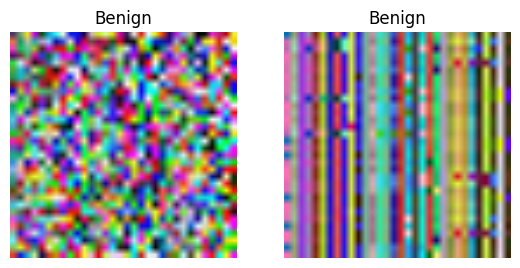

In [182]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_VGG16 = []
all_labels_VGG16 = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_VGG16.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_VGG16.append(predictions)
    all_labels_VGG16.append(label_batch)
    
all_predictions_VGG16 = np.concatenate(all_predictions_VGG16)
all_labels_VGG16 = np.concatenate(all_labels_VGG16)
print('Predictions:\n', all_predictions_VGG16)
print('Labels:\n', all_labels_VGG16)

report_VGG16 = classification_report(all_labels_VGG16, all_predictions_VGG16, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_VGG16[i]])
    plt.axis("off")

val_ds (VGG16)
                  
              precision    recall  f1-score   support

      Benign       0.99      1.00      1.00       642
GPS Spoofing       1.00      0.99      0.99       484

    accuracy                           1.00      1126
   macro avg       1.00      0.99      1.00      1126
weighted avg       1.00      1.00      1.00      1126

                  
1) Accuracy: 0.9955595026642984
                  
2) Precision: 0.9955938187178975
                  
3) Recall: 0.9955595026642984
                  
4) Average F1-score: 0.9955565871846237
                  
5) F1-score for each type of attack: [0.99612102 0.99480789]
                  
6) Average ROC AUC: 0.9948347107438016
                  
7) Average PR AUC: 0.9941099188233049
                  
8) Balanced Accuracy: 0.9948347107438016
                  
9) Hinge: 0.5746003552397868
                  
10) Matthews Correlation Coefficient: 0.9909698687005561
                  
11) Jaccard Score: 0.989669421

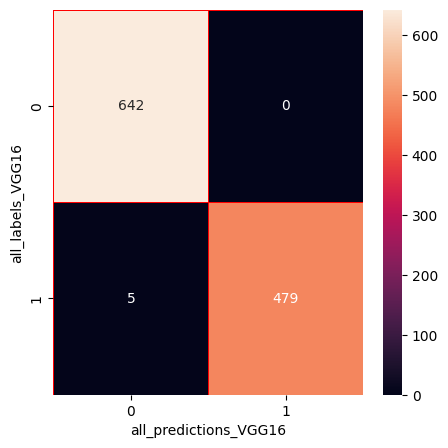

In [183]:
print("val_ds (VGG16)")
print("                  ")
print(report_VGG16)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_VGG16 , all_predictions_VGG16, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_VGG16 , all_predictions_VGG16)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_VGG16 , all_predictions_VGG16)))
print("  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_VGG16 ,all_predictions_VGG16)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions_VGG16")
plt.ylabel("all_labels_VGG16")
plt.show()

In [184]:
loss_val_VGG16, accuracy_val_VGG16 = model_VGG16.evaluate(val_ds)
print("Validation Loss: {:.4f}".format(loss_val_VGG16))
print("Validation Accuracy: {:.4f}".format(accuracy_val_VGG16))

36/36 [==============================] - 3s 42ms/step - loss: 0.0108 - accuracy: 0.9956
Validation Loss: 0.0108
Validation Accuracy: 0.9956


In [185]:
saved_info = {
    'class_names': class_names,
    'all_labels_VGG16': all_labels_VGG16,
    'all_predictions_VGG16': all_predictions_VGG16,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_VGG16 , all_predictions_VGG16),
    'precision_score': precision_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'recall_score': recall_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'f1_score_each': f1_score(all_labels_VGG16 , all_predictions_VGG16, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_VGG16 , all_predictions_VGG16, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_VGG16 , all_predictions_VGG16),
    'Hinge': hinge_loss(all_labels_VGG16 , all_predictions_VGG16),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_VGG16 , all_predictions_VGG16),
    'Jaccard Score': jaccard_score(all_labels_VGG16 , all_predictions_VGG16),
    'Log Loss': log_loss(all_labels_VGG16 , all_predictions_VGG16),
    'Zero-One Loss': zero_one_loss(all_labels_VGG16 , all_predictions_VGG16),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('VGG16_val(TL)_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [186]:
#=========

In [187]:
with open('VGG16_val(TL)_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_VGG16'])
print("  ")
print("predictions:", saved_info['all_predictions_VGG16'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 0 0 ... 0 0 1]
  
predictions: [0 0 0 ... 0 0 1]
  
cm: [[642   0]
 [  5 479]]
  
1) Accuracy: 0.9955595026642984
  
2) Precision: 0.9955938187178975
  
3) Recall: 0.9955595026642984
  
4) Average F1-score: 0.9955565871846237
  
5) F1-score for each type of attack: [0.99612102 0.99480789]
  
6) Average ROC AUC: 0.9948347107438016
  
7) Average PR AUC: 0.9941099188233049
  
8) Balanced Accuracy: 1.0
  
9) Hinge: 0.5746003552397868
  
10) Matthews Correlation Coefficient: 0.9909698687005561
  
11) Jaccard Score: 0.9896694214876033
  
12) Log Loss: 0.16005174684332682
  
13) Zero-One Loss: 0.004440497335701621
  
14) Prediction Overhead: 0.4097222222222222
  
15) Specificity: 1.0


## Load the saved model and learning curve

In [188]:
new_model = tf.keras.models.load_model('./VGG16+TL.h5')

In [189]:
for layer in new_model.layers:
    print(layer.name)
    weights = layer.get_weights()
    for weight in weights:
        print(weight)

input_8
sequential
tf.__operators__.getitem_1
tf.nn.bias_add_1
vgg16
[[[[ 4.29470569e-01  1.17273867e-01  3.40129584e-02 ... -1.32241577e-01
    -5.33475243e-02  7.57738389e-03]
   [ 5.50379455e-01  2.08774377e-02  9.88311544e-02 ... -8.48205537e-02
    -5.11389151e-02  3.74943428e-02]
   [ 4.80015397e-01 -1.72696680e-01  3.75577137e-02 ... -1.27135560e-01
    -5.02991639e-02  3.48965675e-02]]

  [[ 3.73466998e-01  1.62062630e-01  1.70863140e-03 ... -1.48207128e-01
    -2.35300660e-01 -6.30356818e-02]
   [ 4.40074533e-01  4.73412387e-02  5.13819456e-02 ... -9.88498852e-02
    -2.96195745e-01 -7.04357103e-02]
   [ 4.08547401e-01 -1.70375049e-01 -4.96297423e-03 ... -1.22360572e-01
    -2.76450396e-01 -3.90796512e-02]]

  [[-6.13601133e-02  1.35693997e-01 -1.15694344e-01 ... -1.40158370e-01
    -3.77666801e-01 -3.00509870e-01]
   [-8.13870355e-02  4.18543853e-02 -1.01763301e-01 ... -9.43124294e-02
    -5.05662560e-01 -3.83694321e-01]
   [-6.51455522e-02 -1.54351532e-01 -1.38038069e-01 ...

In [190]:
print(new_model.get_config())

{'name': 'model_3', 'trainable': True, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_8'}, 'registered_name': None, 'name': 'input_8', 'inbound_nodes': []}, {'module': 'keras', 'class_name': 'Sequential', 'config': {'name': 'sequential', 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'random_flip_input'}, 'registered_name': None}, {'module': 'keras.layers', 'class_name': 'RandomFlip', 'config': {'name': 'random_flip', 'trainable': True, 'dtype': 'float32', 'mode': 'horizontal_and_vertical', 'seed': None}, 'registered_name': None, 'build_config': {'input_shape': (None, 224, 224, 3)}}, {'module': 'keras.layers', 'class_name': 'RandomRotation', 'config': {'name': 'random_rotation', 'trainable': True, 'dtype': 'float32'

# VGG19 model

In [191]:
IMG_SHAPE = (img_height, img_width,3)
base_model_VGG19 = tf.keras.applications.VGG19(input_shape=IMG_SHAPE, include_top=False, weights='imagenet')

In [192]:
base_model_VGG19.trainable = False
base_model_VGG19.summary()

Model: "vgg19"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_9 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 224, 224, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 224, 224, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 112, 112, 64)      0         
                                                                 
 block2_conv1 (Conv2D)       (None, 112, 112, 128)     73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 112, 112, 128)     147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 56, 56, 128)       0     

In [193]:
image_batch, label_batch = next(iter(train_ds))
feature_batch_VGG19 = base_model_VGG19(image_batch)
print(feature_batch_VGG19.shape)
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
feature_batch_average_VGG19 = global_average_layer(feature_batch_VGG19)
print(feature_batch_average_VGG19.shape)
prediction_layer_VGG19 = tf.keras.layers.Dense(1)
prediction_batch_VGG19 = prediction_layer_VGG19(feature_batch_average_VGG19)
print(prediction_batch_VGG19.shape)

(32, 7, 7, 512)
(32, 512)
(32, 1)


In [194]:
inputs_VGG19 = tf.keras.Input(shape=(img_height, img_width,3))
x_VGG19 = data_augmentation(inputs_VGG19) 
x_VGG19 = tf.keras.applications.vgg19.preprocess_input (x_VGG19)
x_VGG19 = base_model_VGG19(x_VGG19, training=False)
x_VGG19 = global_average_layer(x_VGG19)
x_VGG19 = tf.keras.layers.Dropout(0.2)(x_VGG19) 
outputs_VGG19 = prediction_layer_VGG19(x_VGG19)
model_VGG19 = tf.keras.Model(inputs_VGG19, outputs_VGG19)

In [195]:
class LossHistory(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs={}):
        self.losses = {'batch':[], 'epoch':[]}
        self.accuracy = {'batch':[], 'epoch':[]}
        self.val_loss = {'batch':[], 'epoch':[]}
        self.val_acc = {'batch':[], 'epoch':[]}
        self.history = {}
    def on_batch_end(self, batch, logs={}):
        self.losses['batch'].append(logs.get('loss'))
        self.accuracy['batch'].append(logs.get('accuracy'))
        self.val_loss['batch'].append(logs.get('val_loss'))
        self.val_acc['batch'].append(logs.get('val_accuracy'))
    def on_epoch_end(self, batch, logs={}):
        self.losses['epoch'].append(logs.get('loss'))
        self.accuracy['epoch'].append(logs.get('accuracy'))
        self.val_loss['epoch'].append(logs.get('val_loss'))
        self.val_acc['epoch'].append(logs.get('val_accuracy'))
        self.history = {'loss': self.losses, 'accuracy': self.accuracy, 'val_loss': self.val_loss, 'val_accuracy': self.val_acc}

In [196]:
history= LossHistory()
base_learning_rate = 0.00007
savepath='./VGG19.h5'
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
saveBestModel = kcallbacks.ModelCheckpoint(filepath=savepath, verbose=1, 
                                               save_best_only=True, mode='auto')
model_VGG19.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [197]:
model_VGG19.summary()

Model: "model_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_10 (InputLayer)       [(None, 224, 224, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 tf.__operators__.getitem_2  (None, 224, 224, 3)       0         
  (SlicingOpLambda)                                              
                                                                 
 tf.nn.bias_add_2 (TFOpLamb  (None, 224, 224, 3)       0         
 da)                                                             
                                                                 
 vgg19 (Functional)          (None, 7, 7, 512)         20024384  
                                                                 
 global_average_pooling2d_4  (None, 512)               0   

In [198]:
initial_epochs = 5
loss0, accuracy0 = model_VGG19.evaluate(val_ds)

36/36 [==============================] - 4s 50ms/step - loss: 1.2776 - accuracy: 0.5577


In [199]:
print("initial loss: {:.4f}".format(loss0))
print("initial accuracy: {:.4f}".format(accuracy0))

initial loss: 1.2776
initial accuracy: 0.5577


In [200]:
%%time
history_VGG19 = model_VGG19.fit(train_ds, epochs=initial_epochs, validation_data=val_ds,
                    callbacks=[early_stop, saveBestModel, history])

# Inference (Detection)
start_time = time.time()
detection_results = model_VGG19.predict(val_ds)
end_time = time.time()

detection_time = end_time - start_time

print(f"Detection time: {detection_time} seconds")

Epoch 1/5
213/213 [==============================] - ETA: 0s - loss: 0.6938 - accuracy: 0.7809
Epoch 1: val_loss improved from inf to 0.26562, saving model to ./VGG19.h5
213/213 [==============================] - 15s 65ms/step - loss: 0.6938 - accuracy: 0.7809 - val_loss: 0.2656 - val_accuracy: 0.8908
Epoch 2/5


/usr/local/lib/python3.9/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


213/213 [==============================] - ETA: 0s - loss: 0.2773 - accuracy: 0.9085
Epoch 2: val_loss improved from 0.26562 to 0.14948, saving model to ./VGG19.h5
213/213 [==============================] - 15s 68ms/step - loss: 0.2773 - accuracy: 0.9085 - val_loss: 0.1495 - val_accuracy: 0.9476
Epoch 3/5
212/213 [============================>.] - ETA: 0s - loss: 0.1832 - accuracy: 0.9425
Epoch 3: val_loss improved from 0.14948 to 0.10696, saving model to ./VGG19.h5
213/213 [==============================] - 14s 66ms/step - loss: 0.1825 - accuracy: 0.9427 - val_loss: 0.1070 - val_accuracy: 0.9645
Epoch 4/5
212/213 [============================>.] - ETA: 0s - loss: 0.1354 - accuracy: 0.9579
Epoch 4: val_loss improved from 0.10696 to 0.09479, saving model to ./VGG19.h5
213/213 [==============================] - 14s 64ms/step - loss: 0.1357 - accuracy: 0.9580 - val_loss: 0.0948 - val_accuracy: 0.9725
Epoch 5/5
213/213 [==============================] - ETA: 0s - loss: 0.1116 - accuracy: 0

In [201]:
acc_VGG19 = history_VGG19.history['accuracy']
val_acc_VGG19 = history_VGG19.history['val_accuracy']
loss_VGG19 = history_VGG19.history['loss']
val_loss_VGG19 = history_VGG19.history['val_loss']

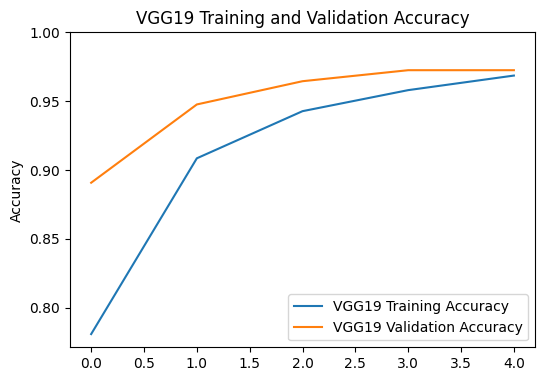

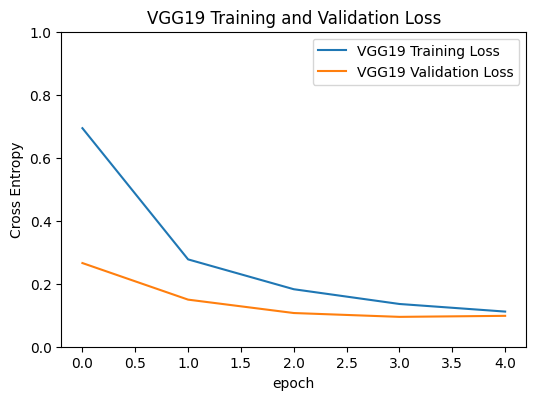

In [202]:
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 1)
plt.plot(acc_VGG19, label='VGG19 Training Accuracy')
plt.plot(val_acc_VGG19, label='VGG19 Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('VGG19 Training and Validation Accuracy')
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 2)
plt.plot(loss_VGG19, label='VGG19 Training Loss')
plt.plot(val_loss_VGG19, label='VGG19 Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('VGG19 Training and Validation Loss')
plt.xlabel('epoch')

plt.savefig('VGG19_Full.pdf', format='pdf', dpi=300)
plt.savefig('VGG19_Full.svg', format='svg')
plt.savefig('VGG19_Full.png', format='png', dpi=300)
plt.show()

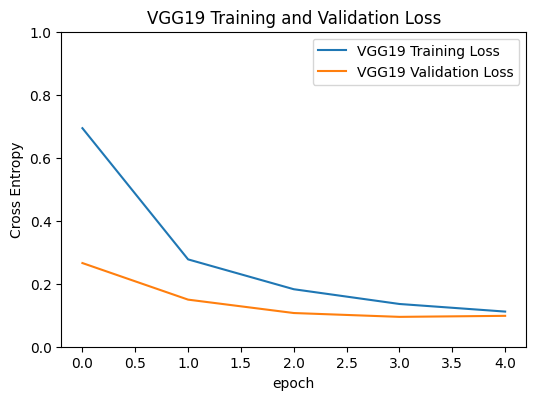

In [203]:
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 2)
plt.plot(loss_VGG19, label='VGG19 Training Loss')
plt.plot(val_loss_VGG19, label='VGG19 Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('VGG19 Training and Validation Loss')
plt.xlabel('epoch')

plt.savefig('VGG19_loss.pdf', format='pdf', dpi=300)
plt.savefig('VGG19_loss.svg', format='svg')
plt.savefig('VGG19_loss.png', format='png', dpi=300)
plt.show()

## Test_ds (VGG19)

Predictions:
 [0 0 0 0 0 0 1 1 1 1 1 1 0 1 1 1 0 1 0 1 0 1 0 0 1 0 1 1 0 0 0 1 1 1 0 0 1
 0 0 1 0 0 0 1 0 0 1 1 0 1 0 1 0 0 0 0 1 1 1 0 0 0 1 1 0 1 0 0 0 0 0 0 0 1
 0 0 1 1 0 1 0 0 0 1 0 0 1 0 1 0 0 1 1 0 1 1 0 0 1 1 0 0 1 0 0 0 0 1 0 1 0
 1 0 0 1 0 1 0 0 0 0 0 0 1 1 1 0 0 0 1 1 0 0 1 0 1 0 1 0 0 0 1 1 1 1 1 0 1
 0 0 1 0 1 1 0 0 1 0 0 1 1 0 0 1 0 0 0 0 1 0 1 1 1 1 0 1 1 0 0 1 1 0 0 0 0
 0 1 0 1 0 1 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 1 1 1 1 0 0 1 0 1
 0 1 0 0 0 0 0 1 1 0 1 0 0 0 0 1 1 1 0 0 1 1 0 1 0 0 0 0 1 0 1 0 1 0 1 1 0
 1 1 0 1 0 1 0 1 0 0 0 0 1 0 1 0 0 0 1 0 1 1 0 0 1 1 0 0 0 0 1 1 1 0 1 1 0
 0 1 0 0 0 0 0 1 1 0 0 1 0 0 1 1 1 0 1 0 0 0 1 1 0 0 0 0 1 0 0 0 1 1 1 0 0
 1 1 0 0 0 0 1 1 1 0 0 0 0 1 0 1 1 1 1 0 0 1 0 0 0 0 1 0 0 1 0 0 1 1 0 0 0
 1 1 0 0 1 0 1 1 0 0 0 0 1 1 0 0 1 1 1 1 0 1 0 0 1 1 0 0 0 0 0 0 0 1 0 0 0
 1 1 0 1 1 0 1 1 0 0 0 1 0 0 1 1 0 1 0 0 0 0 0 1 1 0 0 0 0 0 1 0 0 0 0 0 0
 0 0 0 0 1 0 1 0 1 0 1 0 0 1 0 1 1 1 1 0 1 1 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0
 0 1 0 0 0 

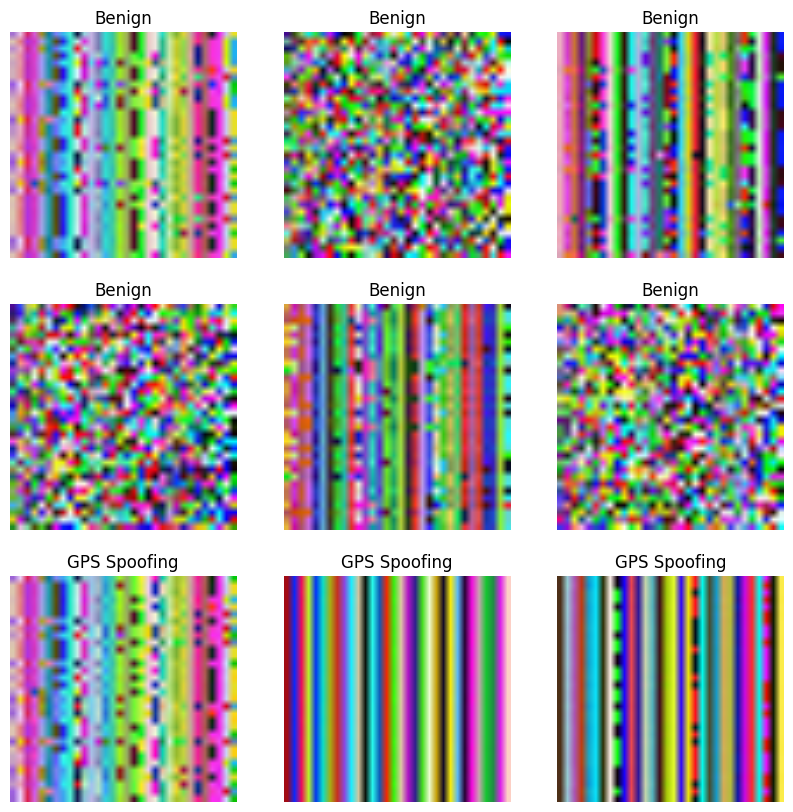

In [204]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_VGG19 = []
all_labels_VGG19 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_VGG19.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_VGG19.append(predictions)
    all_labels_VGG19.append(label_batch)
    
all_predictions_VGG19 = np.concatenate(all_predictions_VGG19)
all_labels_VGG19 = np.concatenate(all_labels_VGG19)
print('Predictions:\n', all_predictions_VGG19)
print('Labels:\n', all_labels_VGG19)

report_VGG19 = classification_report(all_labels_VGG19, all_predictions_VGG19, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_VGG19[i]])
    plt.axis("off")

In [205]:
cm=confusion_matrix(all_labels_VGG19 ,all_predictions_VGG19)
TP = np.sum((all_predictions_VGG19 == 1) & (all_labels_VGG19 == 1))
FP = np.sum((all_predictions_VGG19 == 1) & (all_labels_VGG19 == 0))
FN = np.sum((all_predictions_VGG19 == 0) & (all_labels_VGG19 == 1))
TN = cm[0, 0]
DA = (TP + TN) / len(all_labels_VGG19)
DP = TP / (TP + FP)
DS = TP / (TP + FN)
DF = 2 * (DP * DS) / (DP + DS)
DE = 1 - DA
FR = FP / (FP + TN)
total_predictions = TP + FP + TN + FN
prediction_overhead = (TP + FP) / total_predictions
TN, FP, FN, TP = confusion_matrix(all_labels_VGG19, all_predictions_VGG19).ravel()
specificity = TN / (TN + FP)

test_ds (VGG19)
                  
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99       327
GPS Spoofing       1.00      0.97      0.99       249

    accuracy                           0.99       576
   macro avg       0.99      0.99      0.99       576
weighted avg       0.99      0.99      0.99       576

                  
1) Accuracy: 0.9878472222222222
                  
2) Precision: 0.9881019211576846
                  
3) Recall: 0.9878472222222222
                  
4) Average F1-score: 0.9878249425103193
                  
5) F1-score for each type of attack: [0.98940998 0.98574338]
                  
6) Average ROC AUC: 0.9859437751004017
                  
7) Average PR AUC: 0.984040327978581
                  
8) Balanced Accuracy: 0.9859437751004017
                  
9) Hinge: 0.5798611111111112
                  
10) Matthews Correlation Coefficient: 0.9754581741151652
                  
11) Jaccard Score: 0.971887550

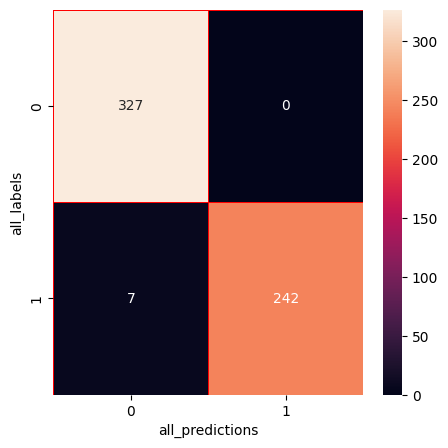

In [206]:
print("test_ds (VGG19)")
print("                  ")
print(report_VGG19)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_VGG19 , all_predictions_VGG19, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_VGG19 , all_predictions_VGG19)))
print("  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_VGG19 ,all_predictions_VGG19)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions")
plt.ylabel("all_labels")
plt.show()

In [207]:
loss_test_VGG19, accuracy_test_VGG19 = model_VGG19.evaluate(test_ds)
print("test loss_VGG19: {:.4f}".format(loss_test_VGG19))
print("test accuracy_VGG19: {:.4f}".format(accuracy_test_VGG19))

18/18 [==============================] - 2s 73ms/step - loss: 0.0797 - accuracy: 0.9809
test loss_VGG19: 0.0797
test accuracy_VGG19: 0.9809


In [208]:
saved_info = {
    'class_names': class_names,
    'all_labels_VGG19': all_labels_VGG19,
    'all_predictions_VGG19': all_predictions_VGG19,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_VGG19 , all_predictions_VGG19),
    'precision_score': precision_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted'),
    'recall_score': recall_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted'),
    'f1_score_each': f1_score(all_labels_VGG19 , all_predictions_VGG19, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_VGG19 , all_predictions_VGG19),
    'Hinge': hinge_loss(all_labels_VGG19 , all_predictions_VGG19),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_VGG19 , all_predictions_VGG19),
    'Jaccard Score': jaccard_score(all_labels_VGG19 , all_predictions_VGG19),
    'Log Loss': log_loss(all_labels_VGG19 , all_predictions_VGG19),
    'Zero-One Loss': zero_one_loss(all_labels_VGG19 , all_predictions_VGG19),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('VGG19_test_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [209]:
with open('VGG19_test_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)
    
print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_VGG19'])
print("  ")
print("predictions:", saved_info['all_predictions_VGG19'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 0 0 0 0 0 1 1 1 1 1 1 0 1 1 1 1 1 0 1 1 1 0 0 1 0 1 1 0 0 0 1 1 1 0 0 1
 0 0 1 0 0 0 1 0 0 1 1 0 1 0 1 0 0 0 0 1 1 1 0 0 1 1 1 0 1 0 0 0 0 0 0 0 1
 0 0 1 1 0 1 0 0 0 1 0 0 1 0 1 0 0 1 1 0 1 1 0 0 1 1 0 0 1 0 0 0 0 1 0 1 0
 1 0 0 1 0 1 0 0 0 0 0 0 1 1 1 0 0 0 1 1 0 0 1 0 1 0 1 0 0 0 1 1 1 1 1 0 1
 0 0 1 0 1 1 0 0 1 0 0 1 1 0 0 1 1 0 0 0 1 0 1 1 1 1 0 1 1 0 0 1 1 0 0 1 0
 0 1 0 1 0 1 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 1 0 0 0 1 1 1 1 0 0 1 0 1
 0 1 0 0 0 0 0 1 1 0 1 0 0 0 0 1 1 1 0 0 1 1 0 1 0 0 0 0 1 0 1 0 1 0 1 1 0
 1 1 0 1 0 1 0 1 0 0 0 0 1 0 1 0 0 0 1 0 1 1 0 0 1 1 0 0 0 0 1 1 1 0 1 1 0
 0 1 0 0 0 0 0 1 1 0 0 1 0 0 1 1 1 0 1 0 0 0 1 1 0 0 0 0 1 0 0 0 1 1 1 1 0
 1 1 0 0 0 0 1 1 1 0 0 0 0 1 0 1 1 1 1 0 0 1 0 0 0 0 1 0 0 1 0 0 1 1 0 0 0
 1 1 0 0 1 0 1 1 0 0 0 0 1 1 0 0 1 1 1 1 0 1 0 0 1 1 0 0 0 0 0 0 0 1 0 0 0
 1 1 0 1 1 0 1 1 0 0 0 1 0 0 1 1 0 1 0 0 0 0 0 1 1 0 0 0 0 0 1 0 0 0 0 0 0
 0 0 0 0 1 0 1 0 1 0 1 0 0 1 0 1 1 1 1 0 1 1 0 1 0 0 0 0 1 0 0 0 0

## Val_ds (VGG19)

Predictions:
 [0 0 1 ... 0 0 0]
Labels:
 [0 0 1 ... 0 0 0]


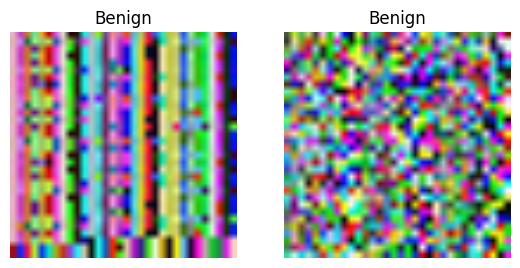

In [210]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_VGG19 = []
all_labels_VGG19 = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_VGG19.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_VGG19.append(predictions)
    all_labels_VGG19.append(label_batch)
    
all_predictions_VGG19 = np.concatenate(all_predictions_VGG19)
all_labels_VGG19 = np.concatenate(all_labels_VGG19)
print('Predictions:\n', all_predictions_VGG19)
print('Labels:\n', all_labels_VGG19)
report_VGG19 = classification_report(all_labels_VGG19 , all_predictions_VGG19, target_names=class_names_s)

plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_VGG19[i]])
    plt.axis("off")

val_ds (VGG19)
                  
              precision    recall  f1-score   support

      Benign       0.97      1.00      0.98       659
GPS Spoofing       1.00      0.95      0.97       467

    accuracy                           0.98      1126
   macro avg       0.98      0.98      0.98      1126
weighted avg       0.98      0.98      0.98      1126

                  
1) Accuracy: 0.9795737122557726
                  
2) Precision: 0.9802625753321909
                  
3) Recall: 0.9795737122557726
                  
4) Average F1-score: 0.979491030710147
                  
5) F1-score for each type of attack: [0.98284862 0.97475302]
                  
6) Average ROC AUC: 0.9753747323340471
                  
7) Average PR AUC: 0.9711757524123216
                  
8) Balanced Accuracy: 0.9753747323340471
                  
9) Hinge: 0.605683836589698
                  
10) Matthews Correlation Coefficient: 0.9584811246443625
                  
11) Jaccard Score: 0.95074946466

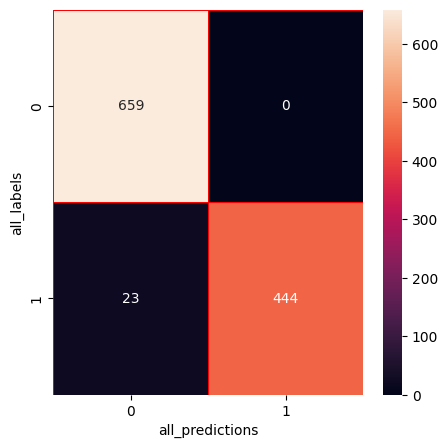

In [211]:
print("val_ds (VGG19)")
print("                  ")
print(report_VGG19)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_VGG19 , all_predictions_VGG19, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_VGG19, all_predictions_VGG19, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_VGG19, all_predictions_VGG19, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_VGG19, all_predictions_VGG19)))
print("  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_VGG19 ,all_predictions_VGG19)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions")
plt.ylabel("all_labels")
plt.show()

In [212]:
loss_val_VGG19, accuracy_val_VGG19 = model_VGG19.evaluate(val_ds)
print("Validation loss_VGG19: {:.4f}".format(loss_val_VGG19))
print("Validation accuracy_VGG19: {:.4f}".format(accuracy_val_VGG19))

36/36 [==============================] - 4s 47ms/step - loss: 0.0867 - accuracy: 0.9742
Validation loss_VGG19: 0.0867
Validation accuracy_VGG19: 0.9742


In [213]:
saved_info = {
    'class_names': class_names,
    'all_labels_VGG19': all_labels_VGG19,
    'all_predictions_VGG19': all_predictions_VGG19,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_VGG19, all_predictions_VGG19),
    'precision_score': precision_score(all_labels_VGG19, all_predictions_VGG19, average='weighted'),
    'recall_score': recall_score(all_labels_VGG19, all_predictions_VGG19, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_VGG19, all_predictions_VGG19, average='weighted'),
    'f1_score_each': f1_score(all_labels_VGG19, all_predictions_VGG19, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_VGG19, all_predictions_VGG19, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_VGG19, all_predictions_VGG19, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_VGG19, all_predictions_VGG19),
    'Hinge': hinge_loss(all_labels_VGG19, all_predictions_VGG19),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_VGG19, all_predictions_VGG19),
    'Jaccard Score': jaccard_score(all_labels_VGG19, all_predictions_VGG19),
    'Log Loss': log_loss(all_labels_VGG19, all_predictions_VGG19),
    'Zero-One Loss': zero_one_loss(all_labels_VGG19, all_predictions_VGG19),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('VGG19_val_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [214]:
with open('VGG19_val_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_VGG19'])
print("  ")
print("predictions:", saved_info['all_predictions_VGG19'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 0 1 ... 0 0 0]
  
predictions: [0 0 1 ... 0 0 0]
  
cm: [[659   0]
 [ 23 444]]
  
1) Accuracy: 0.9795737122557726
  
2) Precision: 0.9802625753321909
  
3) Recall: 0.9795737122557726
  
4) Average F1-score: 0.979491030710147
  
5) F1-score for each type of attack: [0.98284862 0.97475302]
  
6) Average ROC AUC: 0.9753747323340471
  
7) Average PR AUC: 0.9711757524123216
  
8) Balanced Accuracy: 1.0
  
9) Hinge: 0.605683836589698
  
10) Matthews Correlation Coefficient: 0.9584811246443625
  
11) Jaccard Score: 0.9507494646680942
  
12) Log Loss: 0.7362380354793027
  
13) Zero-One Loss: 0.02042628774422739
  
14) Prediction Overhead: 0.4201388888888889
  
15) Specificity: 1.0


## VGG19 + TL

In [215]:
base_model_VGG19.trainable = True
print("Number of layers in the base model: ", len(base_model_VGG19.layers))
fine_tune_at_VGG19 = int((130/151)*len(base_model_VGG19.layers))
for layer in base_model_VGG19.layers[:fine_tune_at_VGG19]:
  layer.trainable = False
print("frozen layers in the base model from layer 1 to ", fine_tune_at_VGG19 )
print("unfrozen layers in the base model from %2d to %3d " % (fine_tune_at_VGG19+1,len(base_model_VGG19.layers)))

Number of layers in the base model:  22
frozen layers in the base model from layer 1 to  18
unfrozen layers in the base model from 19 to  22 


In [216]:
history= LossHistory()
savepath='./VGG19+TL.h5'
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
saveBestModel = kcallbacks.ModelCheckpoint(filepath=savepath, verbose=1, 
                                               save_best_only=True, mode='auto')
model_VGG19.compile(loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
              optimizer = tf.keras.optimizers.Adam(learning_rate=0.00005/10),
              metrics=['accuracy'])
model_VGG19.summary()
len(model_VGG19.trainable_variables)

Model: "model_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_10 (InputLayer)       [(None, 224, 224, 3)]     0         
                                                                 
 sequential (Sequential)     (None, 224, 224, 3)       0         
                                                                 
 tf.__operators__.getitem_2  (None, 224, 224, 3)       0         
  (SlicingOpLambda)                                              
                                                                 
 tf.nn.bias_add_2 (TFOpLamb  (None, 224, 224, 3)       0         
 da)                                                             
                                                                 
 vgg19 (Functional)          (None, 7, 7, 512)         20024384  
                                                                 
 global_average_pooling2d_4  (None, 512)               0   

8

In [217]:
%%time
fine_tune_epochs = 5
total_epochs =  initial_epochs + fine_tune_epochs
history_fine_VGG19 = model_VGG19.fit(train_ds, epochs=total_epochs, initial_epoch=history_VGG19.epoch[-1], 
                         validation_data=val_ds, callbacks=[early_stop, saveBestModel, history])
# Inference (Detection)
start_time = time.time()
detection_results = model_VGG19.predict(val_ds)
end_time = time.time()

detection_time = end_time - start_time

print(f"Detection time: {detection_time} seconds")

Epoch 5/10
213/213 [==============================] - ETA: 0s - loss: 0.0506 - accuracy: 0.9872
Epoch 5: val_loss improved from inf to 0.05907, saving model to ./VGG19+TL.h5
213/213 [==============================] - 22s 95ms/step - loss: 0.0506 - accuracy: 0.9872 - val_loss: 0.0591 - val_accuracy: 0.9822
Epoch 6/10


/usr/local/lib/python3.9/site-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


213/213 [==============================] - ETA: 0s - loss: 0.0239 - accuracy: 0.9915
Epoch 6: val_loss improved from 0.05907 to 0.02614, saving model to ./VGG19+TL.h5
213/213 [==============================] - 18s 86ms/step - loss: 0.0239 - accuracy: 0.9915 - val_loss: 0.0261 - val_accuracy: 0.9893
Epoch 7/10
213/213 [==============================] - ETA: 0s - loss: 0.0154 - accuracy: 0.9950
Epoch 7: val_loss improved from 0.02614 to 0.01008, saving model to ./VGG19+TL.h5
213/213 [==============================] - 19s 90ms/step - loss: 0.0154 - accuracy: 0.9950 - val_loss: 0.0101 - val_accuracy: 0.9938
Epoch 8/10
213/213 [==============================] - ETA: 0s - loss: 0.0140 - accuracy: 0.9949
Epoch 8: val_loss improved from 0.01008 to 0.00517, saving model to ./VGG19+TL.h5
213/213 [==============================] - 17s 79ms/step - loss: 0.0140 - accuracy: 0.9949 - val_loss: 0.0052 - val_accuracy: 0.9991
Epoch 9/10
213/213 [==============================] - ETA: 0s - loss: 0.0073 -

## VGG19 Graph

In [218]:
acc_VGG19 += history_fine_VGG19.history['accuracy']
val_acc_VGG19 += history_fine_VGG19.history['val_accuracy']
loss_VGG19 += history_fine_VGG19.history['loss']
val_loss_VGG19 += history_fine_VGG19.history['val_loss']

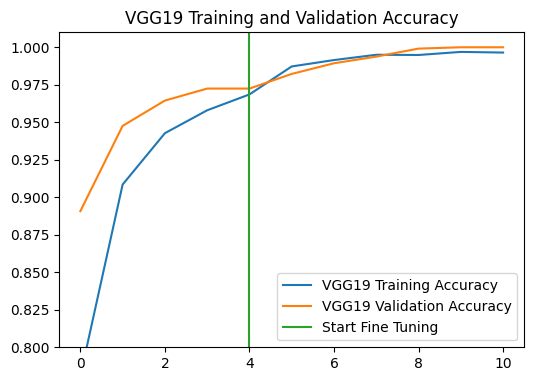

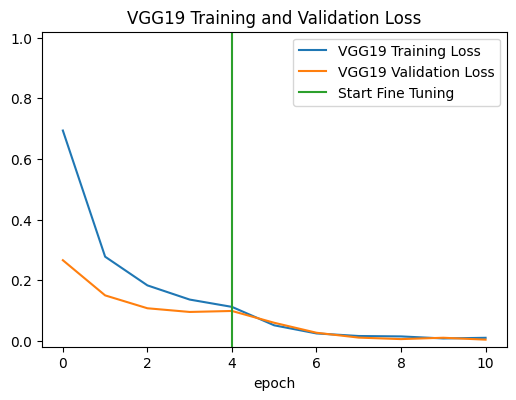

In [219]:
plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 1)
plt.plot(acc_VGG19, label='VGG19 Training Accuracy')
plt.plot(val_acc_VGG19, label='VGG19 Validation Accuracy')
plt.ylim([0.8, 1.01])
plt.plot([initial_epochs-1,initial_epochs-1],
          plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='lower right')
plt.title('VGG19 Training and Validation Accuracy')

plt.figure(figsize=(6, 9))
plt.subplot(2, 1, 2)
plt.plot(loss_VGG19, label='VGG19 Training Loss')
plt.plot(val_loss_VGG19, label='VGG19 Validation Loss')
plt.ylim([-0.02, 1.02])
plt.plot([initial_epochs-1,initial_epochs-1],
         plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='upper right')
plt.title('VGG19 Training and Validation Loss')
plt.xlabel('epoch')

training_history = {}
training_history['train_loss'] = history_VGG19.history['loss']
training_history['val_loss'] = history_VGG19.history['val_loss']
training_history['train_acc'] = history_VGG19.history['accuracy']
training_history['val_acc'] = history_VGG19.history['val_accuracy']

with open('VGG19_TL+ORG.pkl', 'wb') as file:
    pickle.dump(training_history, file)
    
plt.savefig('VGG19_TL+ORG.pdf', format='pdf', dpi=300)
plt.savefig('VGG19_TL+ORG.svg', format='svg')
plt.savefig('VGG19_TL+ORG.png', format='png', dpi=300)
plt.show()

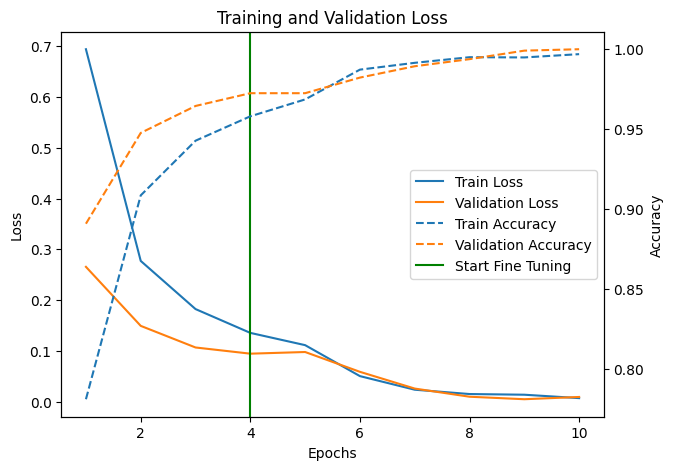

In [220]:
actual_epochs = range(1, total_epochs + 1)
actual_train_loss = loss_VGG19[:total_epochs]
actual_val_loss = val_loss_VGG19[:total_epochs]
actual_train_accuracy = acc_VGG19[:total_epochs]
actual_val_accuracy = val_acc_VGG19[:total_epochs]

fig, ax1 = plt.subplots(figsize=(7, 5))
ax1.plot(actual_epochs, actual_train_loss, '-', label='Train Loss')
ax1.plot(actual_epochs, actual_val_loss, '-', label='Validation Loss')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.set_title('Training and Validation Loss')
ax2 = ax1.twinx()
ax2.plot(actual_epochs, actual_train_accuracy, '--', label='Train Accuracy')
ax2.plot(actual_epochs, actual_val_accuracy, '--', label='Validation Accuracy')
ax2.set_ylabel('Accuracy')

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
custom_legend_elements = handles1 + handles2 + [plt.Line2D([0], [0], color='green', label='Start Fine Tuning')]
custom_legend_labels = labels1 + labels2 + ['Start Fine Tuning']
ax1.legend(custom_legend_elements, custom_legend_labels, loc='center right')
ax1.axvline(x=initial_epochs - 1, color='green')
plot_data = {'fig': fig, 'ax1': ax1, 'ax2': ax2}

learning_curve_data = {
    'train_loss': actual_train_loss,
    'val_loss': actual_val_loss,
    'train_acc': actual_train_accuracy,
    'val_acc': actual_val_accuracy
}

with open('VGG19+Start Fine Tuning.pkl', 'wb') as file:
    pickle.dump(plot_data, file)
    
plt.savefig('VGG19+Start Fine Tuning.pdf', format='pdf', dpi=300)
plt.savefig('VGG19+Start Fine Tuning.svg', format='svg')
plt.savefig('VGG19+Start Fine Tuning.png', format='png', dpi=300)
plt.show()

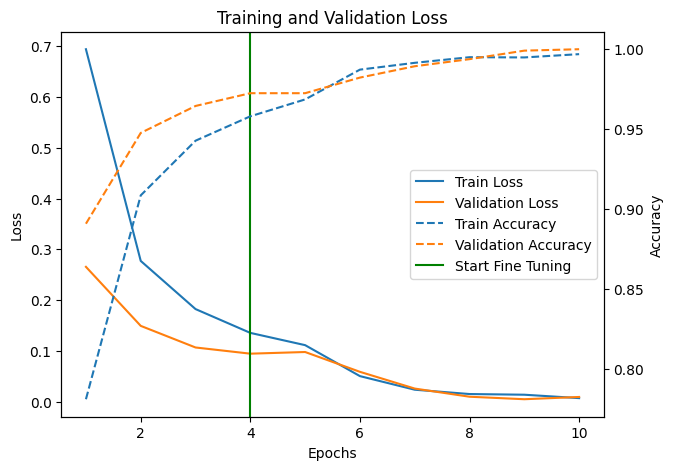

Training Loss: [0.6937755942344666, 0.2772541046142578, 0.1825326383113861, 0.13567104935646057, 0.11155445128679276, 0.05062969774007797, 0.023867398500442505, 0.01537224929779768, 0.0140273068100214, 0.00732586532831192]
Validation Loss: [0.26561811566352844, 0.14948336780071259, 0.10696125030517578, 0.09478624165058136, 0.09805392473936081, 0.05907220020890236, 0.026141103357076645, 0.010081220418214798, 0.0051667517982423306, 0.009615818038582802]
Training Accuracy: [0.7808782458305359, 0.9085034728050232, 0.9427228569984436, 0.9579967856407166, 0.9685710072517395, 0.9872227907180786, 0.9914818406105042, 0.9950066208839417, 0.9948597550392151, 0.9969158172607422]
Validation Accuracy: [0.8907637596130371, 0.9476021528244019, 0.9644760489463806, 0.972468912601471, 0.972468912601471, 0.9822379946708679, 0.9893428087234497, 0.9937832951545715, 0.9991118907928467, 1.0]


In [221]:
with open('VGG19+Start Fine Tuning.pkl', 'rb') as file:
    learning_curve = pickle.load(file)
fig = learning_curve['fig']
ax1 = learning_curve['ax1']
ax2 = learning_curve['ax2']
plt.show()

train_loss = learning_curve_data['train_loss']
val_loss = learning_curve_data['val_loss']
train_acc = learning_curve_data['train_acc']
val_acc = learning_curve_data['val_acc']
print("Training Loss:", learning_curve_data['train_loss'])
print("Validation Loss:", learning_curve_data['val_loss'])
print("Training Accuracy:", learning_curve_data['train_acc'])
print("Validation Accuracy:", learning_curve_data['val_acc'])

## Test_ds(VGG19) + TL

Predictions:
 [1 1 0 1 0 1 1 0 0 1 0 0 0 0 1 0 0 1 1 1 0 0 0 0 1 1 1 0 0 1 0 1 1 1 0 1 0
 1 0 0 0 1 1 0 0 1 1 0 0 1 1 0 0 0 1 0 1 0 1 1 1 0 1 1 0 0 1 0 1 0 0 1 0 0
 1 1 1 1 0 0 0 0 0 1 1 0 1 0 0 0 1 1 1 1 0 1 0 0 1 1 0 0 1 0 0 1 0 1 0 0 0
 1 0 0 0 1 0 0 1 0 1 1 0 0 1 0 1 0 1 1 1 1 1 0 0 0 0 0 1 1 0 0 0 0 1 0 0 0
 0 0 0 1 1 1 0 1 1 0 0 1 0 1 0 0 1 1 1 0 0 0 0 0 0 1 1 0 1 0 1 0 1 0 0 0 0
 0 1 0 1 0 1 0 1 0 0 0 1 1 1 0 0 1 1 1 1 0 1 0 0 0 1 0 0 0 1 0 1 1 0 0 1 0
 0 1 0 1 0 1 0 1 1 0 1 0 1 0 1 1 0 0 1 1 1 0 1 0 0 0 1 1 0 0 0 1 1 0 0 1 1
 1 1 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 1 0 0 1 0 0 1 1 1 0 0 0 0 1 0 1 1 1 0
 0 0 0 1 0 1 0 0 0 1 1 1 1 0 0 0 0 0 1 1 1 0 1 0 1 0 0 1 0 1 1 1 1 1 0 1 1
 1 0 1 0 1 1 1 0 0 0 1 1 1 0 0 0 1 1 1 1 0 0 0 1 1 0 0 0 0 0 0 0 1 0 0 0 1
 1 1 0 0 0 1 0 0 0 0 1 0 1 0 0 1 1 1 0 0 1 1 0 1 0 0 1 1 1 0 1 1 1 0 0 0 1
 0 1 0 0 0 0 0 1 0 1 1 0 0 0 0 0 0 1 1 1 1 1 1 1 0 0 0 0 1 0 1 0 1 0 0 0 1
 1 0 0 0 1 0 0 1 1 0 0 1 0 1 0 1 1 0 0 1 0 0 1 0 1 0 1 1 1 1 0 1 1 1 0 1 0
 0 1 1 0 0 

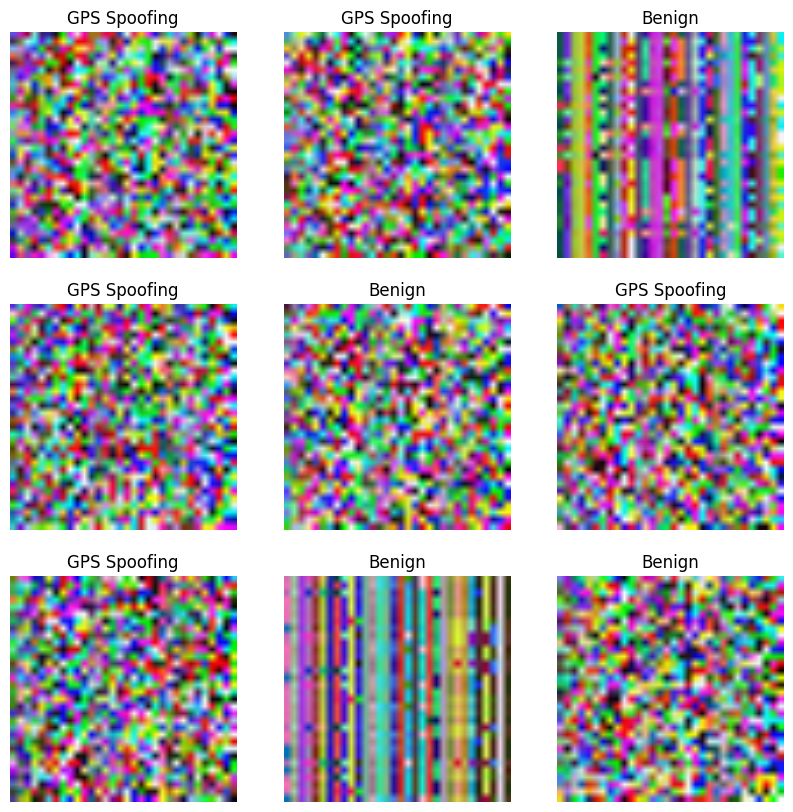

In [222]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_VGG19 = []
all_labels_VGG19 = []

for image_batch, label_batch in test_ds.as_numpy_iterator():
    predictions = model_VGG19.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_VGG19.append(predictions)
    all_labels_VGG19.append(label_batch)

all_predictions_VGG19 = np.concatenate(all_predictions_VGG19)
all_labels_VGG19 = np.concatenate(all_labels_VGG19)
print('Predictions:\n', all_predictions_VGG19)
print('Labels:\n', all_labels_VGG19)

report_VGG19 = classification_report(all_labels_VGG19 , all_predictions_VGG19, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_VGG19[i]])
    plt.axis("off")

test_ds (VGG19)
                  
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00       319
GPS Spoofing       1.00      1.00      1.00       257

    accuracy                           1.00       576
   macro avg       1.00      1.00      1.00       576
weighted avg       1.00      1.00      1.00       576

                  
1) Accuracy: 1.0
                  
2) Precision: 1.0
                  
3) Recall: 1.0
                  
4) Average F1-score: 1.0
                  
5) F1-score for each type of attack: [1. 1.]
                  
6) Average ROC AUC: 1.0
                  
7) Average PR AUC: 1.0
                  
8) Balanced Accuracy: 1.0
                  
9) Hinge: 0.5538194444444444
                  
10) Matthews Correlation Coefficient: 1.0
                  
11) Jaccard Score: 1.0
                  
12) Log Loss: 2.2204460492503136e-16
                  
13) Zero-One Loss 0.0
                  
14) Prediction Overhead : 

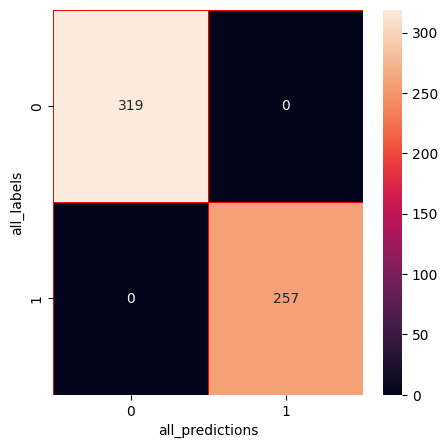

In [223]:
print("test_ds (VGG19)")
print("                  ")
print(report_VGG19)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_VGG19 , all_predictions_VGG19, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_VGG19, all_predictions_VGG19, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_VGG19, all_predictions_VGG19, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))
print("                  ")

cm=confusion_matrix(all_labels_VGG19 ,all_predictions_VGG19)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions")
plt.ylabel("all_labels")
plt.show()

In [224]:
loss_val_VGG19, accuracy_val_VGG19 = model_VGG19.evaluate(test_ds)
print("test loss_VGG19: {:.4f}".format(loss_val_VGG19))
print("test accuracy_VGG19: {:.4f}".format(accuracy_val_VGG19))

18/18 [==============================] - 2s 90ms/step - loss: 0.0027 - accuracy: 1.0000
test loss_VGG19: 0.0027
test accuracy_VGG19: 1.0000


In [225]:
saved_info = {
    'class_names': class_names,
    'all_labels_VGG19': all_labels_VGG19,
    'all_predictions_VGG19': all_predictions_VGG19,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_VGG19, all_predictions_VGG19),
    'precision_score': precision_score(all_labels_VGG19, all_predictions_VGG19, average='weighted'),
    'recall_score': recall_score(all_labels_VGG19, all_predictions_VGG19, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_VGG19, all_predictions_VGG19, average='weighted'),
    'f1_score_each': f1_score(all_labels_VGG19, all_predictions_VGG19, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_VGG19, all_predictions_VGG19, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_VGG19, all_predictions_VGG19, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_VGG19, all_predictions_VGG19),
    'Hinge': hinge_loss(all_labels_VGG19, all_predictions_VGG19),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_VGG19, all_predictions_VGG19),
    'Jaccard Score': jaccard_score(all_labels_VGG19, all_predictions_VGG19),
    'Log Loss': log_loss(all_labels_VGG19, all_predictions_VGG19),
    'Zero-One Loss': zero_one_loss(all_labels_VGG19, all_predictions_VGG19),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('VGG19_test(TL)_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [226]:
#=========

In [227]:
with open('VGG19_test(TL)_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)
    
print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_VGG19'])
print("  ")
print("predictions:", saved_info['all_predictions_VGG19'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])
print("  ")

Class Names: ['0', '1']
  
Label: [1 1 0 1 0 1 1 0 0 1 0 0 0 0 1 0 0 1 1 1 0 0 0 0 1 1 1 0 0 1 0 1 1 1 0 1 0
 1 0 0 0 1 1 0 0 1 1 0 0 1 1 0 0 0 1 0 1 0 1 1 1 0 1 1 0 0 1 0 1 0 0 1 0 0
 1 1 1 1 0 0 0 0 0 1 1 0 1 0 0 0 1 1 1 1 0 1 0 0 1 1 0 0 1 0 0 1 0 1 0 0 0
 1 0 0 0 1 0 0 1 0 1 1 0 0 1 0 1 0 1 1 1 1 1 0 0 0 0 0 1 1 0 0 0 0 1 0 0 0
 0 0 0 1 1 1 0 1 1 0 0 1 0 1 0 0 1 1 1 0 0 0 0 0 0 1 1 0 1 0 1 0 1 0 0 0 0
 0 1 0 1 0 1 0 1 0 0 0 1 1 1 0 0 1 1 1 1 0 1 0 0 0 1 0 0 0 1 0 1 1 0 0 1 0
 0 1 0 1 0 1 0 1 1 0 1 0 1 0 1 1 0 0 1 1 1 0 1 0 0 0 1 1 0 0 0 1 1 0 0 1 1
 1 1 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 1 0 0 1 0 0 1 1 1 0 0 0 0 1 0 1 1 1 0
 0 0 0 1 0 1 0 0 0 1 1 1 1 0 0 0 0 0 1 1 1 0 1 0 1 0 0 1 0 1 1 1 1 1 0 1 1
 1 0 1 0 1 1 1 0 0 0 1 1 1 0 0 0 1 1 1 1 0 0 0 1 1 0 0 0 0 0 0 0 1 0 0 0 1
 1 1 0 0 0 1 0 0 0 0 1 0 1 0 0 1 1 1 0 0 1 1 0 1 0 0 1 1 1 0 1 1 1 0 0 0 1
 0 1 0 0 0 0 0 1 0 1 1 0 0 0 0 0 0 1 1 1 1 1 1 1 0 0 0 0 1 0 1 0 1 0 0 0 1
 1 0 0 0 1 0 0 1 1 0 0 1 0 1 0 1 1 0 0 1 0 0 1 0 1 0 1 1 1 1 0 1 1

## Val_ds (VGG19) + TL

Predictions:
 [0 0 0 ... 0 1 1]
Labels:
 [0 0 0 ... 0 1 1]


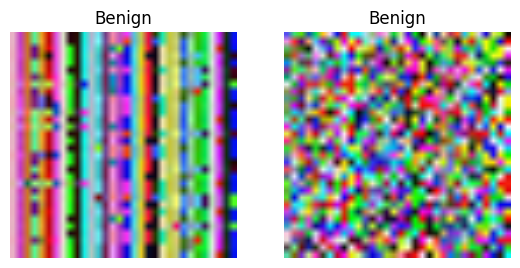

In [228]:
class_names_s = ['Benign', 'GPS Spoofing']
all_predictions_VGG19 = []
all_labels_VGG19 = []

for image_batch, label_batch in val_ds.as_numpy_iterator():
    predictions = model_VGG19.predict_on_batch(image_batch).flatten()
    predictions = tf.nn.sigmoid(predictions)
    predictions = tf.where(predictions < 0.5, 0, 1)
    all_predictions_VGG19.append(predictions)
    all_labels_VGG19.append(label_batch)

all_predictions_VGG19 = np.concatenate(all_predictions_VGG19)
all_labels_VGG19 = np.concatenate(all_labels_VGG19)
print('Predictions:\n', all_predictions_VGG19)
print('Labels:\n', all_labels_VGG19)

report_VGG19 = classification_report(all_labels_VGG19 , all_predictions_VGG19, target_names=class_names_s)
plt.figure(figsize=(10, 10))
for i in range(2):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(image_batch[i].astype("uint8"))
    plt.title(class_names_s[all_predictions_VGG19[i]])
    plt.axis("off")

val_ds (VGG19)
                  
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00       657
GPS Spoofing       1.00      1.00      1.00       469

    accuracy                           1.00      1126
   macro avg       1.00      1.00      1.00      1126
weighted avg       1.00      1.00      1.00      1126

                  
1) Accuracy: 1.0
                  
2) Precision: 1.0
                  
3) Recall: 1.0
                  
4) Average F1-score: 1.0
                  
5) F1-score for each type of attack: [1. 1.]
                  
6) Average ROC AUC: 1.0
                  
7) Average PR AUC: 1.0
                  
8) Balanced Accuracy: 1.0
                  
9) Hinge: 0.58348134991119
                  
10) Matthews Correlation Coefficient: 1.0
                  
11) Jaccard Score: 1.0
                  
12) Log Loss: 2.2204460492503136e-16
                  
13) Zero-One Loss 0.0
  
14) Prediction Overhead : 0.4201
            

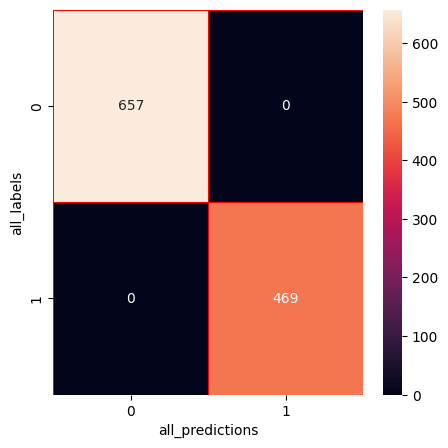

In [229]:
print("val_ds (VGG19)")
print("                  ")
print(report_VGG19)
print("                  ")

print("1) Accuracy: "+ str(accuracy_score(all_labels_VGG19 , all_predictions_VGG19)))
print("                  ")
print("2) Precision: "+ str(precision_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("3) Recall: "+ str(recall_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("4) Average F1-score: "+ str(f1_score(all_labels_VGG19 , all_predictions_VGG19, average='weighted')))
print("                  ")
print("5) F1-score for each type of attack: "+ str(f1_score(all_labels_VGG19 , all_predictions_VGG19, average=None)))
print("                  ")
print("6) Average ROC AUC: " + str(roc_auc_score(all_labels_VGG19, all_predictions_VGG19, average='weighted')))
print("                  ")
print("7) Average PR AUC: " + str(average_precision_score(all_labels_VGG19, all_predictions_VGG19, average='weighted')))
print("                  ")
print("8) Balanced Accuracy: "+ str(balanced_accuracy_score(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("9) Hinge: "+ str(hinge_loss(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("10) Matthews Correlation Coefficient: "+ str(matthews_corrcoef(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("11) Jaccard Score: "+ str(jaccard_score(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("12) Log Loss: "+ str(log_loss(all_labels_VGG19, all_predictions_VGG19)))
print("                  ")
print("13) Zero-One Loss "+ str(zero_one_loss(all_labels_VGG19, all_predictions_VGG19)))
print("  ")
print("14) Prediction Overhead : {:.4f}".format(prediction_overhead))
print("                  ")
print("15) Specificity: : {:.4f}".format(specificity))

cm=confusion_matrix(all_labels_VGG19 ,all_predictions_VGG19)
f,ax=plt.subplots(figsize=(5,5))
sns.heatmap(cm,annot=True,linewidth=0.5,linecolor="red",fmt=".0f",ax=ax)
plt.xlabel("all_predictions")
plt.ylabel("all_labels")
plt.show()

In [230]:
loss_test_VGG19, accuracy_test_VGG19 = model_VGG19.evaluate(val_ds)
print("Validation loss_VGG19: {:.4f}".format(loss_test_VGG19))
print("Validation accuracy_VGG19: {:.4f}".format(accuracy_test_VGG19))

36/36 [==============================] - 4s 53ms/step - loss: 0.0032 - accuracy: 1.0000
Validation loss_VGG19: 0.0032
Validation accuracy_VGG19: 1.0000


In [231]:
#=========

In [232]:
saved_info = {
    'class_names': class_names,
    'all_labels_VGG19': all_labels_VGG19,
    'all_predictions_VGG19': all_predictions_VGG19,
    'cm': cm,
    'accuracy_score': accuracy_score(all_labels_VGG19, all_predictions_VGG19),
    'precision_score': precision_score(all_labels_VGG19, all_predictions_VGG19, average='weighted'),
    'recall_score': recall_score(all_labels_VGG19, all_predictions_VGG19, average='weighted'),
    'f1_score_weighted': f1_score(all_labels_VGG19, all_predictions_VGG19, average='weighted'),
    'f1_score_each': f1_score(all_labels_VGG19, all_predictions_VGG19, average=None),
    'roc_auc_score_weighted': roc_auc_score(all_labels_VGG19, all_predictions_VGG19, average='weighted'),
    'average_precision_score_weighted': average_precision_score(all_labels_VGG19, all_predictions_VGG19, average='weighted'),
    'Balanced Accuracy': balanced_accuracy_score(all_labels_VGG19, all_predictions_VGG19),
    'Hinge': hinge_loss(all_labels_VGG19, all_predictions_VGG19),
    'Matthews Correlation Coefficient': matthews_corrcoef(all_labels_VGG19, all_predictions_VGG19),
    'Jaccard Score': jaccard_score(all_labels_VGG19, all_predictions_VGG19),
    'Log Loss': log_loss(all_labels_VGG19, all_predictions_VGG19),
    'Zero-One Loss': zero_one_loss(all_labels_VGG19, all_predictions_VGG19),
    'Prediction Overhead': prediction_overhead,
    'Specificity': specificity,
}

with open('VGG19_val(TL)_info.pkl', 'wb') as file:
    pickle.dump(saved_info, file)

In [233]:
with open('VGG19_val(TL)_info.pkl', 'rb') as file:
    saved_info = pickle.load(file)

print("Class Names:", saved_info['class_names'])
print("  ")
print("Label:",saved_info['all_labels_VGG19'])
print("  ")
print("predictions:", saved_info['all_predictions_VGG19'])
print("  ")
print("cm:", saved_info['cm'])
print("  ")
print("1) Accuracy:", saved_info['accuracy_score'])
print("  ")
print("2) Precision:", saved_info['precision_score'])
print("  ")
print("3) Recall:", saved_info['recall_score'])
print("  ")
print("4) Average F1-score:", saved_info['f1_score_weighted'])
print("  ")
print("5) F1-score for each type of attack:", saved_info['f1_score_each'])
print("  ")
print("6) Average ROC AUC:", saved_info['roc_auc_score_weighted'])
print("  ")
print("7) Average PR AUC:", saved_info['average_precision_score_weighted'])
print("  ")
print("8) Balanced Accuracy:", saved_info['Specificity'])
print("  ")
print("9) Hinge:", saved_info['Hinge'])
print("  ")
print("10) Matthews Correlation Coefficient:", saved_info['Matthews Correlation Coefficient'])
print("  ")
print("11) Jaccard Score:", saved_info['Jaccard Score'])
print("  ")
print("12) Log Loss:", saved_info['Log Loss'])
print("  ")
print("13) Zero-One Loss:", saved_info['Zero-One Loss'])
print("  ")
print("14) Prediction Overhead:", saved_info['Prediction Overhead'])
print("  ")
print("15) Specificity:", saved_info['Specificity'])

Class Names: ['0', '1']
  
Label: [0 0 0 ... 0 1 1]
  
predictions: [0 0 0 ... 0 1 1]
  
cm: [[657   0]
 [  0 469]]
  
1) Accuracy: 1.0
  
2) Precision: 1.0
  
3) Recall: 1.0
  
4) Average F1-score: 1.0
  
5) F1-score for each type of attack: [1. 1.]
  
6) Average ROC AUC: 1.0
  
7) Average PR AUC: 1.0
  
8) Balanced Accuracy: 1.0
  
9) Hinge: 0.58348134991119
  
10) Matthews Correlation Coefficient: 1.0
  
11) Jaccard Score: 1.0
  
12) Log Loss: 2.2204460492503136e-16
  
13) Zero-One Loss: 0.0
  
14) Prediction Overhead: 0.4201388888888889
  
15) Specificity: 1.0


## Load the saved model and learning curve

In [234]:
new_model = tf.keras.models.load_model('./VGG19+TL.h5')

In [235]:
for layer in new_model.layers:
    print(layer.name)
    weights = layer.get_weights()
    for weight in weights:
        print(weight)

input_10
sequential
tf.__operators__.getitem_2
tf.nn.bias_add_2
vgg19
[[[[ 0.34119523  0.09563112  0.0177449  ... -0.11436455 -0.05099866
    -0.00299793]
   [ 0.46418372  0.03355668  0.10245045 ... -0.06945956 -0.04020201
     0.04048637]
   [ 0.39416704 -0.08419707 -0.03631314 ... -0.10720515 -0.03804016
     0.04690642]]

  [[ 0.33999205  0.13363543  0.02129423 ... -0.13025227 -0.16508926
    -0.06969624]
   [ 0.41810837  0.05260524  0.09755926 ... -0.09385028 -0.20492788
    -0.0573062 ]
   [ 0.37740308 -0.07876257 -0.04775979 ... -0.11827433 -0.19008617
    -0.01889699]]

  [[-0.04484424  0.06471398 -0.07631404 ... -0.12629718 -0.29905206
    -0.2825364 ]
   [-0.04806903 -0.00658076 -0.02234544 ... -0.0878844  -0.3915486
    -0.34632796]
   [-0.04594866 -0.11583115 -0.14462094 ... -0.12290562 -0.35782176
    -0.27979308]]]


 [[[ 0.23215917  0.133657    0.12134422 ... -0.1063385   0.28406844
     0.3594997 ]
   [ 0.30511212  0.05677647  0.21688674 ... -0.06828708  0.3440761
     0

In [236]:
print(new_model.get_config())

{'name': 'model_4', 'trainable': True, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_10'}, 'registered_name': None, 'name': 'input_10', 'inbound_nodes': []}, {'module': 'keras', 'class_name': 'Sequential', 'config': {'name': 'sequential', 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_input_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'random_flip_input'}, 'registered_name': None}, {'module': 'keras.layers', 'class_name': 'RandomFlip', 'config': {'name': 'random_flip', 'trainable': True, 'dtype': 'float32', 'mode': 'horizontal_and_vertical', 'seed': None}, 'registered_name': None, 'build_config': {'input_shape': (None, 224, 224, 3)}}, {'module': 'keras.layers', 'class_name': 'RandomRotation', 'config': {'name': 'random_rotation', 'trainable': True, 'dtype': 'float3